🔍 Parsing directory tree structures...
✅ Target folders synchronized. Found 400 active sample pairs.
📊 Auditing Index [1/4] -> File: 180.jpg | Verified Active Classes: [0, 3, 4, 5, 6, 7]
📊 Auditing Index [2/4] -> File: 204.jpg | Verified Active Classes: [0, 2, 3, 4, 6, 7]
📊 Auditing Index [3/4] -> File: 525.jpg | Verified Active Classes: [0, 1, 3, 4, 5, 6, 7]
📊 Auditing Index [4/4] -> File: 122.jpg | Verified Active Classes: [0, 1, 3, 4, 6, 7]


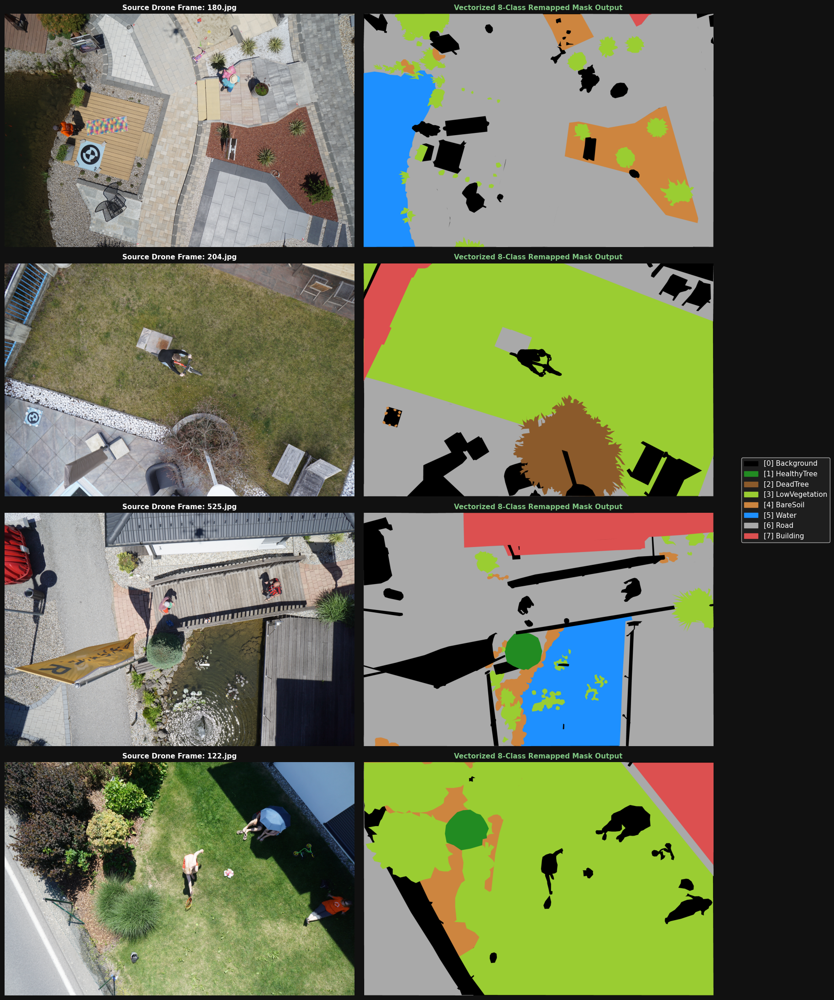

In [1]:
# =============================================================================
# SKY INNOVATORS — VECTORIZED RGB MASK SANITY TESTER (v1.2 — 8-CLASS UPDATED)
# Aligned to: Background, HealthyTree, DeadTree, LowVeg, BareSoil, Water, Road, Building
# =============================================================================

import os
import cv2
import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── 1. CONFIGURATION PATHS ───────────────────────────────────────────────────
IMAGE_DIR = "/kaggle/input/datasets/awsaf49/semantic-drone-dataset/semantic_drone_dataset/training_set/images"
MASK_DIR  = "/kaggle/input/datasets/awsaf49/semantic-drone-dataset/semantic_drone_dataset/training_set/gt/semantic/label_images"

NUM_SAMPLES_TO_PLOT = 4

# ── 2. SCHEMA DEFINITIONS (Your updated 8-Class Layout Configuration) ────────
CLASS_NAMES = ["Background", "HealthyTree", "DeadTree", "LowVegetation", "BareSoil", "Water", "Road", "Building"]
NUM_CLASSES = len(CLASS_NAMES)

CLASS_COLORS = np.array([
    [  0,   0,   0],  # 0  Background      black
    [ 34, 139,  34],  # 1  HealthyTree     forest green
    [139,  90,  43],  # 2  DeadTree        brown
    [154, 205,  50],  # 3  LowVegetation   yellow-green
    [205, 133,  63],  # 4  BareSoil        sandy brown
    [ 30, 144, 255],  # 5  Water           dodger blue
    [169, 169, 169],  # 6  Road            gray
    [220,  80,  80],  # 7  Building        red
], dtype=np.uint8)

# ── 3. BUILD UPDATED 8-CLASS VECTORIZED HASH ENGINE ─────────────────────────
DRONE_RGB_TO_CLASS = {
    (128, 64, 128): 1, (130, 76, 0): 2, (0, 102, 0): 3, (112, 103, 87): 4,
    (28, 42, 168): 5, (48, 41, 30): 6, (0, 50, 89): 7, (107, 142, 35): 8,
    (70, 70, 70): 9, (102, 102, 156): 10, (254, 228, 12): 11, (254, 148, 12): 12,
    (190, 153, 153): 13, (153, 153, 153): 14, (255, 22, 96): 15, (102, 51, 0): 16,
    (9, 143, 150): 17, (119, 11, 32): 18, (51, 51, 0): 19, (190, 250, 190): 20,
    (112, 150, 146): 21, (2, 135, 115): 22,
}

# Synced explicitly to match your new index destinations
DRONE_REMAP = {
    0: 0,  # unlabeled     -> Background (0)
    1: 6,  # paved-area    -> Road (6)
    2: 4,  # dirt          -> BareSoil (4)
    3: 3,  # grass         -> LowVegetation (3)
    4: 6,  # gravel        -> Road (6)
    5: 5,  # water         -> Water (5)
    6: 4,  # rocks         -> BareSoil (4)
    7: 5,  # pool          -> Water (5)
    8: 3,  # vegetation    -> LowVegetation (3)
    9: 7,  # roof          -> Building (7)
    10: 7, # wall          -> Building (7)
    11: 7, # window        -> Building (7)
    12: 7, # door          -> Building (7)
    13: 0, # fence         -> Background (0)
    14: 0, # fence-pole    -> Background (0)
    15: 0, # person        -> Background (0)
    16: 0, # dog           -> Background (0)
    17: 0, # car           -> Background (0)
    18: 0, # bicycle       -> Background (0)
    19: 1, # tree          -> HealthyTree (1)
    20: 2, # bald-tree     -> DeadTree (2)  <-- CRITICAL TARGET
    21: 0, # ar-marker     -> Background (0)
    22: 0  # obstacle      -> Background (0)
}

# Pre-compile the flat master lookup hash table across the 256^3 colorspace matrix
_RGB_HASH_TABLE = np.zeros(256**3, dtype=np.uint8)
for (r, g, b), original_class in DRONE_RGB_TO_CLASS.items():
    remapped_target_class = DRONE_REMAP[original_class]
    _RGB_HASH_TABLE[r*65536 + g*256 + b] = remapped_target_class

def fast_rgb_mask_to_8class(mask_path):
    """Loads RGB color masks and maps them natively into 0-7 index representations."""
    mask_pil = Image.open(mask_path).convert("RGB")
    mask_rgb = np.array(mask_pil)
    r = mask_rgb[:, :, 0].astype(np.int32)
    g = mask_rgb[:, :, 1].astype(np.int32)
    b = mask_rgb[:, :, 2].astype(np.int32)
    flat_keys = r*65536 + g*256 + b
    return _RGB_HASH_TABLE[flat_keys]

# ── 4. EXECUTE VISUAL AUDIT LOOP ─────────────────────────────────────────────
try:
    print("🔍 Parsing directory tree structures...")
    image_exts = ('.jpg', '.jpeg', '.png', '.tif', '.tiff')
    
    all_imgs = sorted([f for f in os.listdir(IMAGE_DIR) if f.lower().endswith(image_exts)])
    mask_index = {os.path.splitext(f)[0].lower(): os.path.join(MASK_DIR, f) for f in os.listdir(MASK_DIR) if f.lower().endswith(('.png', '.jpg', '.jpeg'))}
    
    matched_pairs = []
    for img_name in all_imgs:
        stem = os.path.splitext(img_name)[0].lower()
        if stem in mask_index:
            matched_pairs.append((os.path.join(IMAGE_DIR, img_name), mask_index[stem], img_name))
            
    print(f"✅ Target folders synchronized. Found {len(matched_pairs)} active sample pairs.")
    
    sampled_pairs = random.sample(matched_pairs, min(NUM_SAMPLES_TO_PLOT, len(matched_pairs)))
    
    # Initialize dashboard plotting canvas
    fig, axes = plt.subplots(len(sampled_pairs), 2, figsize=(16, 5.5 * len(sampled_pairs)), facecolor="#111")
    if len(sampled_pairs) == 1: axes = np.expand_dims(axes, axis=0)
        
    legend_patches = [mpatches.Patch(color=CLASS_COLORS[c]/255., label=f"[{c}] {CLASS_NAMES[c]}") for c in range(NUM_CLASSES)]
    
    for row, (img_path, mask_path, filename) in enumerate(sampled_pairs):
        img_rgb = np.array(Image.open(img_path).convert("RGB"))
        
        # Vectorized translation pass into the updated 8-class matrix space
        mask_index_map = fast_rgb_mask_to_8class(mask_path)
        colorized_mask = CLASS_COLORS[mask_index_map]
        
        unique_classes = np.unique(mask_index_map)
        print(f"📊 Auditing Index [{row+1}/{len(sampled_pairs)}] -> File: {filename} | Verified Active Classes: {unique_classes.tolist()}")
        
        # Panel 1: Original Source Photo
        axes[row, 0].imshow(img_rgb)
        axes[row, 0].set_title(f"Source Drone Frame: {filename}", color="white", fontsize=11, fontweight="bold")
        axes[row, 0].axis("off")
        
        # Panel 2: Correctly Remapped Target Mask
        axes[row, 1].imshow(colorized_mask)
        axes[row, 1].set_title("Vectorized 8-Class Remapped Mask Output", color="#81c784", fontsize=11, fontweight="bold")
        axes[row, 1].axis("off")
        
    fig.legend(handles=legend_patches, loc="center right", facecolor="#222", labelcolor="white", bbox_to_anchor=(1.15, 0.5), fontsize=11)
    plt.tight_layout()
    plt.show()
    
except Exception as e:
    print(f"❌ Diagnostic script execution aborted: {e}")

|UAvid dataset

🔍 Synchronizing file indices inside target UAVid sequence directory...
✅ Scanning Complete. Found 600 active matched matrix assets inside seq1.
📊 Auditing Index [1/3] -> Frame: shifted160.png | Active Mapped Classes Sighted: [0, 1, 3, 6, 7]
📊 Auditing Index [2/3] -> Frame: shifted15.png | Active Mapped Classes Sighted: [0, 1, 3, 6, 7]
📊 Auditing Index [3/3] -> Frame: shifted16.png | Active Mapped Classes Sighted: [0, 1, 3, 6, 7]


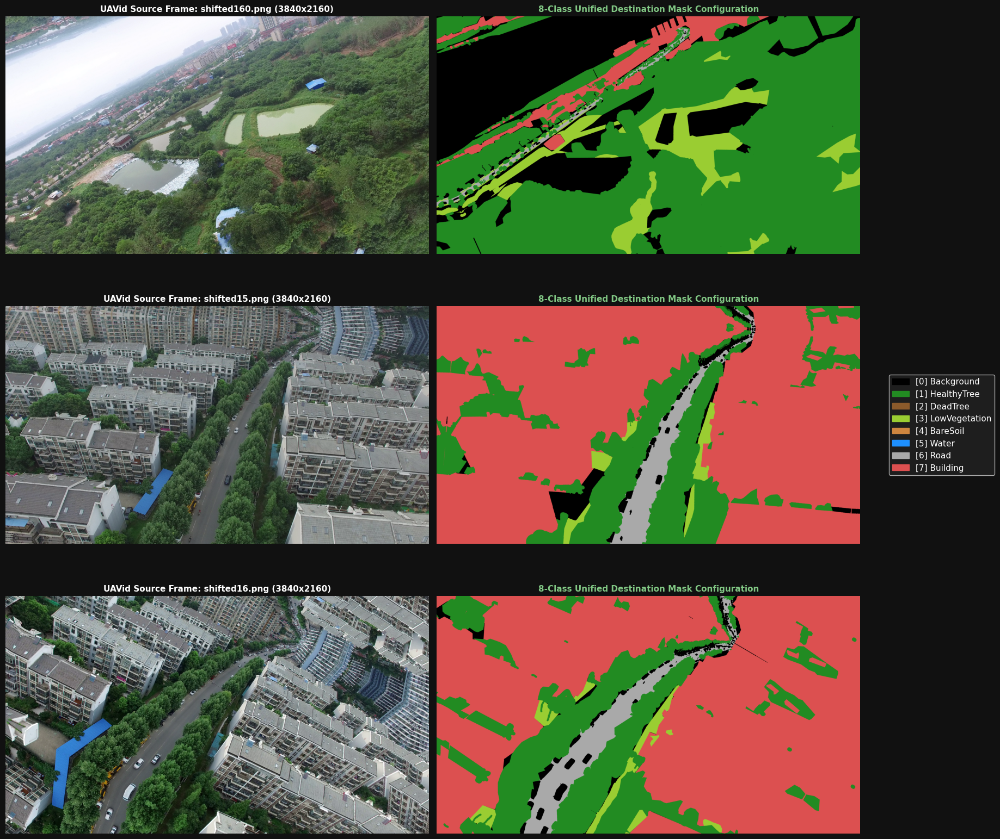

In [2]:
# =============================================================================
# SKY INNOVATORS — UAVID-V1 SEQUENCE SANITY TESTER (v1.3 — 8-CLASS ALIGNED)
# Direct path validation, color remapping, and twin matrix canvas plotter
# =============================================================================

import os
import cv2
import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── 1. TARGET PATH CONFIGURATION (Your explicit seq1 paths) ──────────────────
IMAGE_DIR = "/kaggle/input/datasets/dasmehdixtr/uavid-v1/uavid_train/seq1/Images"
MASK_DIR  = "/kaggle/input/datasets/dasmehdixtr/uavid-v1/uavid_train/seq1/Labels"

NUM_SAMPLES_TO_PLOT = 3

# ── 2. SCHEMA DEFINITIONS (Your strict 8-Class Production Layout) ────────────
CLASS_NAMES = ["Background", "HealthyTree", "DeadTree", "LowVegetation", "BareSoil", "Water", "Road", "Building"]
NUM_CLASSES = len(CLASS_NAMES)

CLASS_COLORS = np.array([
    [  0,   0,   0],  # 0  Background      black
    [ 34, 139,  34],  # 1  HealthyTree     forest green
    [139,  90,  43],  # 2  DeadTree        brown
    [154, 205,  50],  # 3  LowVegetation   yellow-green
    [205, 133,  63],  # 4  BareSoil        sandy brown
    [ 30, 144, 255],  # 5  Water           dodger blue
    [169, 169, 169],  # 6  Road            gray
    [220,  80,  80],  # 7  Building        red
], dtype=np.uint8)

# ── 3. BUILD THE UAVID-SPECIFIC RGB MASTER HASH TABLE ────────────────────────
# Maps native UAVid mask colors directly to your target 8-Class indices
UAVID_RGB_TO_8CLASS = {
    (  0,   0,   0): 0,   # Background clutter -> Background (0)
    (  0, 128,   0): 1,   # Tree               -> HealthyTree (1)
    (128, 128,   0): 3,   # Low vegetation     -> LowVegetation (3)
    (128,   0,   0): 7,   # Building           -> Building (7)
    (128,  64, 128): 6,   # Road               -> Road (6)
    ( 64,   0, 128): 0,   # Moving car         -> Background (0)
    ( 64,  64,   0): 0,   # Human              -> Background (0)
    (192,   0, 192): 0,   # Static car         -> Background (0)
}

# Pre-compile the flat master lookup matrix array over the 256^3 colorspace
_RGB_HASH_TABLE = np.zeros(256**3, dtype=np.uint8)
for (r, g, b), target_class in UAVID_RGB_TO_8CLASS.items():
    _RGB_HASH_TABLE[r*65536 + g*256 + b] = target_class

def fast_uavid_mask_to_8class(mask_path):
    """Parses UAVid source color layers natively into the 0-7 production scale."""
    mask_pil = Image.open(mask_path).convert("RGB")
    mask_rgb = np.array(mask_pil)
    r = mask_rgb[:, :, 0].astype(np.int32)
    g = mask_rgb[:, :, 1].astype(np.int32)
    b = mask_rgb[:, :, 2].astype(np.int32)
    flat_keys = r*65536 + g*256 + b
    return _RGB_HASH_TABLE[flat_keys]

# ── 4. RUN SEQUENCE AUDIT AND PLOT VISUAL RESPONSES ─────────────────────────
try:
    print("🔍 Synchronizing file indices inside target UAVid sequence directory...")
    
    # UAVid typically pairs matching names directly (e.g., 000000.png in both folders)
    image_extensions = ('.png', '.jpg', '.jpeg')
    all_imgs = sorted([f for f in os.listdir(IMAGE_DIR) if f.lower().endswith(image_extensions)])
    
    matched_pairs = []
    for filename in all_imgs:
        mask_path = os.path.join(MASK_DIR, filename)
        if os.path.exists(mask_path):
            matched_pairs.append((os.path.join(IMAGE_DIR, filename), mask_path, filename))
            
    print(f"✅ Scanning Complete. Found {len(matched_pairs)} active matched matrix assets inside seq1.")
    
    if len(matched_pairs) == 0:
        raise FileNotFoundError("❌ Missing File Anomaly: Check if filenames match perfectly between your Images and Labels directories.")
        
    sampled_pairs = random.sample(matched_pairs, min(NUM_SAMPLES_TO_PLOT, len(matched_pairs)))
    
    # Establish Dark Dashboard Structure
    fig, axes = plt.subplots(len(sampled_pairs), 2, figsize=(16, 5.5 * len(sampled_pairs)), facecolor="#111")
    if len(sampled_pairs) == 1: axes = np.expand_dims(axes, axis=0)
        
    legend_patches = [mpatches.Patch(color=CLASS_COLORS[c]/255., label=f"[{c}] {CLASS_NAMES[c]}") for c in range(NUM_CLASSES)]
    
    for row, (img_path, mask_path, filename) in enumerate(sampled_pairs):
        img_rgb = np.array(Image.open(img_path).convert("RGB"))
        
        # Fast vectorized bitstream lookups
        mask_index_map = fast_uavid_mask_to_8class(mask_path)
        colorized_mask = CLASS_COLORS[mask_index_map]
        
        unique_classes = np.unique(mask_index_map)
        print(f"📊 Auditing Index [{row+1}/{len(sampled_pairs)}] -> Frame: {filename} | Active Mapped Classes Sighted: {unique_classes.tolist()}")
        
        # Column 01: Raw Drone Source Frame
        axes[row, 0].imshow(img_rgb)
        axes[row, 0].set_title(f"UAVid Source Frame: {filename} ({img_rgb.shape[1]}x{img_rgb.shape[0]})", color="white", fontsize=11, fontweight="bold")
        axes[row, 0].axis("off")
        
        # Column 02: Remapped High-Impact Training Target Mask
        axes[row, 1].imshow(colorized_mask)
        axes[row, 1].set_title("8-Class Unified Destination Mask Configuration", color="#81c784", fontsize=11, fontweight="bold")
        axes[row, 1].axis("off")
        
    fig.legend(handles=legend_patches, loc="center right", facecolor="#222", labelcolor="white", bbox_to_anchor=(1.15, 0.5), fontsize=11)
    plt.tight_layout()
    plt.show()
    
except Exception as e:
    print(f"❌ Verification Pipeline Aborted: {e}")

# loveda dataset

🚀 Initializing Cross-Domain LoveDA Synchronization Loop...
  ✓ [Rural] Domain Synchronized: 1366 matching asset pairs found.
  ✓ [Urban] Domain Synchronized: 1156 matching asset pairs found.

✅ Total Pooled LoveDA Dataset Slices: 2522 entries loaded successfully.
📊 Auditing row [1/4] | Domain: Rural | File: 840.png | Sighted Classes: [0, 1, 3, 5, 6]
📊 Auditing row [2/4] | Domain: Rural | File: 1260.png | Sighted Classes: [0, 3, 5, 6]
📊 Auditing row [3/4] | Domain: Urban | File: 1881.png | Sighted Classes: [0, 1, 6, 7]
📊 Auditing row [4/4] | Domain: Rural | File: 286.png | Sighted Classes: [0, 1, 4, 6]


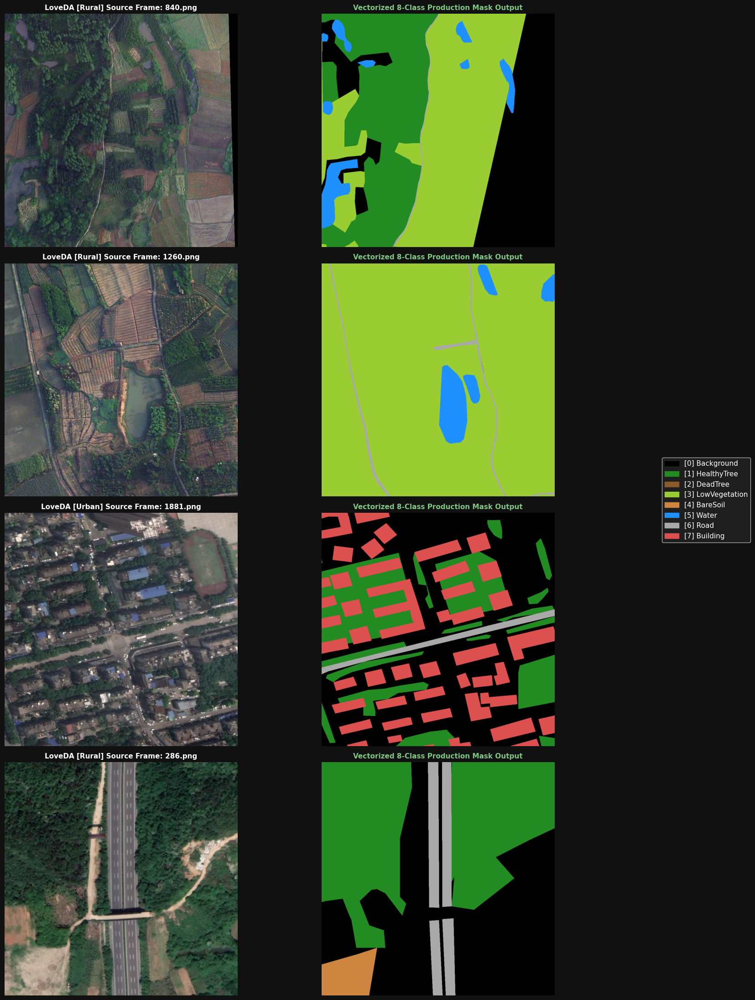

In [3]:
# =============================================================================
# SKY INNOVATORS — LOVEDA CROSS-DOMAIN SANITY TESTER (v1.4 — 8-CLASS ALIGNED)
# Vectorized cross-domain remapping and multi-environmental dashboard loader
# =============================================================================

import os
import cv2
import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── 1. MULTI-DOMAIN FOLDER CONFIGURATION ─────────────────────────────────────
LOVEDA_CONFIGS = {
    "Rural": {
        "images": "/kaggle/input/datasets/mohammedjaveed/loveda-dataset/Train/Train/Rural/images_png",
        "masks": "/kaggle/input/datasets/mohammedjaveed/loveda-dataset/Train/Train/Rural/masks_png"
    },
    "Urban": {
        "images": "/kaggle/input/datasets/mohammedjaveed/loveda-dataset/Train/Train/Urban/images_png",
        "masks": "/kaggle/input/datasets/mohammedjaveed/loveda-dataset/Train/Train/Urban/masks_png"
    }
}

# ── 2. PRODUCTION SCHEMA DEFINITIONS ─────────────────────────────────────────
CLASS_NAMES = ["Background", "HealthyTree", "DeadTree", "LowVegetation", "BareSoil", "Water", "Road", "Building"]
NUM_CLASSES = len(CLASS_NAMES)

CLASS_COLORS = np.array([
    [  0,   0,   0],  # 0  Background      (Black)
    [ 34, 139,  34],  # 1  HealthyTree     (Forest Green)
    [139,  90,  43],  # 2  DeadTree        (Brown)
    [154, 205,  50],  # 3  LowVegetation   (Yellow-Green)
    [205, 133,  63],  # 4  BareSoil        (Sandy Brown)
    [ 30, 144, 255],  # 5  Water           (Dodger Blue)
    [169, 169, 169],  # 6  Road            (Gray)
    [220,  80,  80],  # 7  Building        (Red)
], dtype=np.uint8)

# ── 3. LOVEDA VECTORIZED TRANSLATION MATRIX LOOKUP ───────────────────────────
# Native LoveDA indexing profile: 
# 0:Ignore, 1:Background, 2:Building, 3:Road, 4:Water, 5:Barren, 6:Forest, 7:Agriculture
LOVEDA_REMAP_ARRAY = np.array([
    0,  # 0 (Ignore)      -> Background (0)
    0,  # 1 (Background)  -> Background (0)
    7,  # 2 (Building)    -> Building (7)
    6,  # 3 (Road)        -> Road (6)
    5,  # 4 (Water)       -> Water (5)
    4,  # 5 (Barren)      -> BareSoil (4)
    1,  # 6 (Forest)      -> HealthyTree (1)
    3   # 7 (Agriculture) -> LowVegetation (3)
], dtype=np.uint8)

def remap_loveda_mask(mask_path):
    """Loads a raw single-channel LoveDA mask and remaps indices via vectorization."""
    gray = np.array(Image.open(mask_path).convert("L"))
    # Fast array-based index substitution boundary clamp
    return LOVEDA_REMAP_ARRAY[np.clip(gray, 0, 7)]

# ── 4. EXECUTE CO-REGISTRATION & VERIFICATION PASSTHROUGH ───────────────────
try:
    print("🚀 Initializing Cross-Domain LoveDA Synchronization Loop...")
    all_synchronized_pairs = []

    for domain_name, paths in LOVEDA_CONFIGS.items():
        if not (os.path.exists(paths["images"]) and os.path.exists(paths["masks"])):
            print(f"⚠️ Path slice missing for domain environment: {domain_name}. Skipping...")
            continue
            
        img_files = sorted([f for f in os.listdir(paths["images"]) if f.lower().endswith('.png')])
        mask_files = set([f for f in os.listdir(paths["masks"]) if f.lower().endswith('.png')])
        
        domain_pairs_count = 0
        for fname in img_files:
            if fname in mask_files:
                all_synchronized_pairs.append({
                    "domain": domain_name,
                    "img_path": os.path.join(paths["images"], fname),
                    "mask_path": os.path.join(paths["masks"], fname),
                    "filename": fname
                })
                domain_pairs_count += 1
        print(f"  ✓ [{domain_name}] Domain Synchronized: {domain_pairs_count} matching asset pairs found.")

    print(f"\n✅ Total Pooled LoveDA Dataset Slices: {len(all_synchronized_pairs)} entries loaded successfully.")
    
    if len(all_synchronized_pairs) == 0:
        raise FileNotFoundError("❌ System Crash: Zero file matches discovered. Double check your Kaggle repository mounting states.")

    # Sample precisely 4 elements to print across alternate environments
    sampled_entries = random.sample(all_synchronized_pairs, min(4, len(all_synchronized_pairs)))

    # Construct Display Grid
    fig, axes = plt.subplots(len(sampled_entries), 2, figsize=(16, 5.5 * len(sampled_entries)), facecolor="#111")
    if len(sampled_entries) == 1: axes = np.expand_dims(axes, axis=0)

    legend_patches = [mpatches.Patch(color=CLASS_COLORS[c]/255., label=f"[{c}] {CLASS_NAMES[c]}") for c in range(NUM_CLASSES)]

    for row, entry in enumerate(sampled_entries):
        img_rgb = np.array(Image.open(entry["img_path"]).convert("RGB"))
        
        # Run translation lookup matrix channel pass
        remapped_mask = remap_loveda_mask(entry["mask_path"])
        color_mask = CLASS_COLORS[remapped_mask]
        
        unique_classes = np.unique(remapped_mask)
        print(f"📊 Auditing row [{row+1}/4] | Domain: {entry['domain']:5s} | File: {entry['filename']} | Sighted Classes: {unique_classes.tolist()}")

        # Left Column: Raw Aerial Imagery Data
        axes[row, 0].imshow(img_rgb)
        axes[row, 0].set_title(f"LoveDA [{entry['domain']}] Source Frame: {entry['filename']}", color="white", fontsize=11, fontweight="bold")
        axes[row, 0].axis("off")

        # Right Column: Clean Vectorized Rescaled Output Target Mask
        axes[row, 1].imshow(color_mask)
        axes[row, 1].set_title("Vectorized 8-Class Production Mask Output", color="#81c784", fontsize=11, fontweight="bold")
        axes[row, 1].axis("off")

    fig.legend(handles=legend_patches, loc="center right", facecolor="#222", labelcolor="white", bbox_to_anchor=(1.15, 0.5), fontsize=11)
    plt.tight_layout()
    plt.show()

except Exception as core_exception:
    print(f"❌ Structural Audit Terminal Failure: {core_exception}")

# Aerial deadtree 

In [ ]:
# =============================================================================
# SKY INNOVATORS — PARALLEL VISUAL CHECKER (v2.2 — FIXED TYPO)
# Overlays mask boundaries onto the image to verify dataset alignment
# =============================================================================

import os
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# ── 1. EXACT TARGET FILES ────────────────────────────────────────────────────
IMAGE_PATH = "/kaggle/input/datasets/meteahishali/aerial-imagery-for-standing-dead-tree-segmentation/USA_segmentation/RGB_images/RGB_ar037_2019_n_06_04_0.png"
MASK_PATH  = "/kaggle/input/datasets/meteahishali/aerial-imagery-for-standing-dead-tree-segmentation/USA_segmentation/masks/mask_ar037_2019_n_06_04_0.png"

# ── 2. DATA CHECK & VISUAL OVERLAY ENGINE ────────────────────────────────────
try:
    if not os.path.exists(IMAGE_PATH) or not os.path.exists(MASK_PATH):
        raise FileNotFoundError("Verify file paths. One or both target files are missing.")

    # Load resources
    img_bgr = cv2.imread(IMAGE_PATH)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # Load mask natively as grayscale
    mask_gray = np.array(Image.open(MASK_PATH).convert("L"))
    
    # ── VERIFICATION STATS ──
    total_pixels = mask_gray.size
    dead_tree_pixels = np.sum(mask_gray > 0)
    mortality_percentage = (dead_tree_pixels / total_pixels) * 100.0
    
    print("="*60)
    print("📊 DATASET INTEGRITY VERIFICATION REPORT")
    print("="*60)
    print(f"File Name      : {os.path.basename(IMAGE_PATH)}")
    print(f"Image Size     : {img_rgb.shape[1]}x{img_rgb.shape[0]} px")
    print(f"Total Pixels   : {total_pixels:,}")
    print(f"Dead Wood Area : {dead_tree_pixels:,} pixels ({mortality_percentage:.3f}%)")
    print("="*60)

    # ── GENERATE VISUAL BOUNDARY OVERLAY ──
    # Create a binary mask of the dead tree pixels (value 255 where true)
    binary_mask = np.zeros_like(mask_gray, dtype=np.uint8)
    binary_mask[mask_gray > 0] = 255
    
    # FIX: Corrected spelling from cv2.RETRIVE_EXTERNAL to cv2.RETR_EXTERNAL
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # Draw the contours as a bright red line directly on top of a copy of the image
    overlay_img = img_rgb.copy()
    cv2.drawContours(overlay_img, contours, -1, (255, 0, 0), thickness=2)

    # ── DISPLAY PARALLEL CANVAS PANEL ──
    fig, axes = plt.subplots(1, 3, figsize=(20, 7), facecolor="#111")
    
    # Panel 1: Original Image
    axes[0].imshow(img_rgb)
    axes[0].set_title("1. Original RGB Drone Image", color="white", fontsize=12, fontweight="bold")
    axes[0].axis("off")
    
    # Panel 2: Raw Mask Intensity
    axes[1].imshow(binary_mask, cmap="gray")
    axes[1].set_title(f"2. Extracted Target Mask ({dead_tree_pixels:,} px)", color="#81c784", fontsize=12, fontweight="bold")
    axes[1].axis("off")
    
    # Panel 3: Verification Overlay
    axes[2].imshow(overlay_img)
    axes[2].set_title("3. Parallel Verification Overlay", color="#ffb74d", fontsize=12, fontweight="bold")
    axes[2].axis("off")
    
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"❌ Verification Failure: {e}")

# Train the model using segformer with 3 dataet Aeiral,semantic and uavid

In [ ]:
!pip install  segmentation_models_pytorch

#  The best model until now V10

In [ ]:
# =============================================================================
# SKY INNOVATORS PRODUCTION PLATFORM — v10.0 LANDSCAPE BIOMASS MODEL
# Pure SegFormer-B4 Backbone | 8-Class | 3 Balanced Core Datasets
# =============================================================================

import os
os.environ['PYTORCH_ALLOC_CONF'] = 'expandable_segments:True'

import gc, sys, time, random
import numpy as np
import cv2
from PIL import Image
from glob import glob
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import albumentations as A
from albumentations.pytorch import ToTensorV2
from transformers import SegformerForSemanticSegmentation

# ── ENVIRONMENT INITIALIZATION ────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True

def seed_everything(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_everything(42)

print(f"Device : {device}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

# ── OPTIMIZED LANDSCAPE INTERFACE PARAMETERS ──────────────────────────────────
NUM_CLASSES   = 8  # FIXED: Dropped Fire class
IMG_SIZE      = 640
BATCH_SIZE    = 2
ACCUM_STEPS   = 4
EPOCHS        = 40
BASE_LR       = 6e-5
PATIENCE      = 12
MIN_DELTA     = 1e-4
WEIGHT_DECAY  = 0.01
IGNORE_INDEX  = -100

# Local model asset assignment targets Kaggle system directory natively
SEGFORMER_LOCAL    = "/kaggle/input/models/nvidia/segformer/pytorch/b4-finetuned-ade-512-512/1"
SEGFORMER_MODEL_ID = "nvidia/segformer-b4-finetuned-ade-512-512"
SAVE_PATH          = "/kaggle/working/sky_innovators_v10_landscape.pth"

CLASS_NAMES = [
    "Background", "HealthyTree", "DeadTree", "LowVegetation",
    "BareSoil", "Water", "Road", "Building"
]

CLASS_COLORS = np.array([
    [  0,   0,   0], [ 34, 139,  34], [139,  90,  43], [154, 205,  50],
    [205, 133,  63], [ 30, 144, 255], [169, 169, 169], [220,  80,  80]
], dtype=np.uint8)

# Class Weights rebalanced to focus heavy attention on forestry classes without Fire skew
CLASS_WEIGHTS = torch.tensor(
    [1.0, 1.5, 1.5, 1.0, 1.0, 1.0, 1.0, 1.0],
    dtype=torch.float32).to(device)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ── PATH MAPS ─────────────────────────────────────────────────────────────────
SD_IMG  = "/kaggle/input/datasets/awsaf49/semantic-drone-dataset/semantic_drone_dataset/training_set/images"
SD_MASK = "/kaggle/input/datasets/awsaf49/semantic-drone-dataset/semantic_drone_dataset/training_set/gt/semantic/label_images"
UAVID   = "/kaggle/input/datasets/dasmehdixtr/uavid-v1"
DEAD_I  = "/kaggle/input/datasets/meteahishali/aerial-imagery-for-standing-dead-tree-segmentation/USA_segmentation/RGB_images"
DEAD_M  = "/kaggle/input/datasets/meteahishali/aerial-imagery-for-standing-dead-tree-segmentation/USA_segmentation/masks"

# ── HASH CONVERSION DICTIONARIES ──────────────────────────────────────────────
DRONE_RGB_TO_CLASS = {
    (128,64,128):1,(130,76,0):2,(0,102,0):3,(112,103,87):4,(28,42,168):5,
    (48,41,30):6,(0,50,89):7,(107,142,35):8,(70,70,70):9,(102,102,156):10,
    (254,228,12):11,(254,148,12):12,(190,153,153):13,(153,153,153):14,
    (255,22,96):15,(102,51,0):16,(9,143,150):17,(119,11,32):18,
    (51,51,0):19,(190,250,190):20,(112,150,146):21,(2,135,115):22}

DRONE_REMAP = {
    0:0,1:6,2:4,3:3,4:6,5:5,6:4,7:5,8:3,9:7,10:7,11:7,12:7,
    13:0,14:0,15:0,16:0,17:0,18:0,19:1,20:2,21:0,22:0}

_DH = np.zeros(256**3, dtype=np.uint8)
for (r,g,b),o in DRONE_RGB_TO_CLASS.items(): _DH[r*65536+g*256+b] = DRONE_REMAP[o]

_UH = np.zeros(256**3, dtype=np.uint8)
for (r,g,b),c in {(0,0,0):0,(0,128,0):1,(128,128,0):3,(128,0,0):7,
                   (128,64,128):6,(64,0,128):0,(64,64,0):0,(192,0,192):0}.items():
    _UH[r*65536+g*256+b] = c

# ── TRANSFORM INTERFACES ──────────────────────────────────────────────────────
train_tf = A.Compose([
    A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.3), A.RandomRotate90(p=0.4),
    A.Affine(scale=(0.85,1.15), translate_percent=0.10, rotate=(-44,44), p=0.5),
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=(-0.25,0.20), contrast_limit=(-0.20,0.20)),
        A.CLAHE(clip_limit=3.0),
    ], p=0.6),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2(),
])
val_tf = A.Compose([A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2()])

# =============================================================================
# STORAGE CLASSES
# =============================================================================
class CachedDS(Dataset):
    def __init__(self, transform, name=""):
        self.transform = transform
        self.images, self.masks, self.name = [], [], name
    def add(self, img, mask):
        self.images.append(img); self.masks.append(mask)
    def __len__(self): return len(self.images)
    def __getitem__(self, idx):
        img, mask = self.images[idx], self.masks[idx]
        if (mask == IGNORE_INDEX).any():
            ign   = (mask == IGNORE_INDEX).astype(np.uint8)
            valid = np.where(ign, 0, mask).astype(np.uint8)
            aug   = self.transform(image=img, mask=valid)
            msk_t = aug["mask"].long()
            ign_r = cv2.resize(ign, (msk_t.shape[1], msk_t.shape[0]), interpolation=cv2.INTER_NEAREST)
            msk_t[torch.from_numpy(ign_r.astype(bool))] = IGNORE_INDEX
        else:
            aug   = self.transform(image=img, mask=mask.astype(np.uint8))
            msk_t = aug["mask"].long()
        return {"pixel_values": aug["image"], "labels": msk_t}

def _ri(img): return cv2.resize(img,(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_LINEAR)
def _rm(m):   return cv2.resize(m.astype(np.float32),(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_NEAREST).astype(np.int16)

# =============================================================================
# DATA LOADERS PIPELINE
# =============================================================================
def build_master_dataloaders():
    print(f"\n📦 Loading pure {NUM_CLASSES}-class landscape pipeline into RAM...")
    t0 = time.time()
    
    # 1. Semantic Drone Split
    all_sd = sorted(glob(os.path.join(SD_IMG,"*.jpg")))
    random.shuffle(all_sd)
    n_val  = max(1, int(len(all_sd)*0.20))
    sd_val, sd_train = all_sd[:n_val], all_sd[n_val:]
    
    def _load_sd(paths, tf, name):
        ds = CachedDS(tf, name)
        midx = {os.path.splitext(f)[0].lower(): os.path.join(SD_MASK,f)
                for f in os.listdir(SD_MASK) if f.lower().endswith('.png')}
        print(f"  🧠 {name} ({len(paths)})...")
        for p in tqdm(paths, leave=False, mininterval=10):
            stem = os.path.splitext(os.path.basename(p))[0].lower()
            if stem not in midx: continue
            img  = _ri(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
            m    = np.array(Image.open(midx[stem]).convert("RGB"))
            r,g,b = (m[:,:,c].astype(np.int32) for c in range(3))
            ds.add(img, _rm(_DH[r*65536+g*256+b].astype(np.int16)))
        return ds
        
    tr_sd = _load_sd(sd_train, train_tf, "SemanticDrone-train")
    vl_sd = _load_sd(sd_val,   val_tf,   "SemanticDrone-val")

    # 2. UAVid Split
    all_uavid = []
    for split in ["uavid_train","uavid_val"]:
        sdir = os.path.join(UAVID,split)
        if not os.path.exists(sdir): continue
        for seq in sorted(glob(os.path.join(sdir,"seq*"))):
            idir, ldir = os.path.join(seq,"Images"), os.path.join(seq,"Labels")
            if not (os.path.exists(idir) and os.path.exists(ldir)): continue
            for f in os.listdir(idir):
                if f.lower().endswith('.png'):
                    lp = os.path.join(ldir, f)
                    if os.path.exists(lp):   
                        all_uavid.append((os.path.join(idir,f), lp))
                        
    random.shuffle(all_uavid)
    n_vl = max(1, int(len(all_uavid)*0.10))
    uavid_val, uavid_train = all_uavid[:n_vl], all_uavid[n_vl:]
    
    def _load_uavid(pairs, tf, name):
        ds = CachedDS(tf, name)
        print(f"  🧠 {name} ({len(pairs)})...")
        for ip,mp in tqdm(pairs, leave=False, mininterval=10):
            img = _ri(cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB))
            m   = np.array(Image.open(mp).convert("RGB"))
            r,g,b = (m[:,:,c].astype(np.int32) for c in range(3))
            ds.add(img, _rm(_UH[r*65536+g*256+b].astype(np.int16)))
        return ds
        
    tr_uavid = _load_uavid(uavid_train, train_tf, "UAVid-train")
    vl_uavid = _load_uavid(uavid_val,   val_tf,   "UAVid-val")

    # 3. USA Standing Dead Tree
    all_dead = [(os.path.join(DEAD_I,f), os.path.join(DEAD_M,f"mask_{f[4:]}"))
                for f in os.listdir(DEAD_I)
                if f.startswith("RGB_") and f.lower().endswith('.png')
                and os.path.exists(os.path.join(DEAD_M,f"mask_{f[4:]}"))]
    random.shuffle(all_dead)
    n_vl_d = max(1, int(len(all_dead)*0.10))
    dead_val, dead_train = all_dead[:n_vl_d], all_dead[n_vl_d:]
    
    def _load_dead(pairs, tf, name):
        ds = CachedDS(tf, name)
        print(f"  🧠 {name} ({len(pairs)})...")
        for ip,mp in tqdm(pairs, leave=False, mininterval=10):
            img  = _ri(cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB))
            gray = np.array(Image.open(mp).convert("L"))
            mask = np.full(gray.shape, IGNORE_INDEX, dtype=np.int16)
            mask[gray>0] = 2
            ds.add(img, _rm(mask))
        return ds
        
    tr_dead = _load_dead(dead_train, train_tf, "USADead-train")
    vl_dead = _load_dead(dead_val,   val_tf,   "USADead-val")

    # Amalgamate all structural data layers cleanly (FLAME3 Streams completely removed)
    train_pool = ConcatDataset([tr_sd, tr_uavid, tr_dead])
    val_pool   = ConcatDataset([vl_sd, vl_uavid, vl_dead])
    
    print(f"\n  ✅ Cache done ({time.time()-t0:.0f}s)")
    print(f"     Train : {len(train_pool):,}  (SD + UAVid + USADead)")
    print(f"     Val   : {len(val_pool):,}  (SD + UAVid + USADead)")
    
    is_cu = torch.cuda.is_available()
    tr_loader = DataLoader(train_pool, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=is_cu)
    vl_loader = DataLoader(val_pool,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=is_cu)
    return tr_loader, vl_loader

# =============================================================================
# MODEL ARCHITECTURE HUBS
# =============================================================================
def build_segformer():
    model_source = (SEGFORMER_LOCAL if os.path.exists(SEGFORMER_LOCAL) else SEGFORMER_MODEL_ID)
    print(f"🎬 Loading SegFormer-B4 from: {model_source}")
    return SegformerForSemanticSegmentation.from_pretrained(
        model_source,
        num_labels=NUM_CLASSES,
        id2label={i:n for i,n in enumerate(CLASS_NAMES)},
        label2id={n:i for i,n in enumerate(CLASS_NAMES)},
        ignore_mismatched_sizes=True,
    ).to(device)

def save_ckpt(mdl, opt, epoch, best_miou, iou_list):
    torch.save({
        "epoch": epoch, "model_state_dict": mdl.state_dict(),
        "optimizer_state_dict": opt.state_dict(),
        "best_miou": best_miou, "per_class_iou": iou_list,
        "num_classes": NUM_CLASSES, "class_names": CLASS_NAMES,
    }, SAVE_PATH)

# =============================================================================
# PYTORCH BALANCED MULTICLASS CE + DICE INTERFACES
# =============================================================================
def loss_fn(pred, tgt):
    ce   = F.cross_entropy(pred, tgt, weight=CLASS_WEIGHTS, ignore_index=IGNORE_INDEX)
    soft = F.softmax(pred, dim=1)
    tgt_oh = F.one_hot(torch.clamp(tgt,0,NUM_CLASSES-1), NUM_CLASSES).permute(0,3,1,2).float()
    vm     = (tgt != IGNORE_INDEX).unsqueeze(1)
    inter  = torch.sum(soft*vm * tgt_oh*vm, dim=(0,2,3))
    denom  = torch.sum((soft+tgt_oh)*vm,    dim=(0,2,3))
    dice   = torch.sum((1-(2*inter+1e-6)/(denom+1e-6)) * CLASS_WEIGHTS) / CLASS_WEIGHTS.sum()
    return 0.5*ce + 0.5*dice

def _upd(tp, union, p, t):
    pf,tf = p.ravel(), t.ravel()
    v = tf != IGNORE_INDEX
    pv,tv = pf[v],tf[v]
    for c in range(NUM_CLASSES):
        tp[c]    += np.sum((pv==c)&(tv==c))
        union[c] += np.sum((pv==c)|(tv==c))

def _iou(tp,union):
    iou = np.where(union>0, tp/(union+1e-9), np.nan)
    return iou, float(np.nanmean(iou))

def print_iou(iou, ep):
    print(f"\n  Per-class IoU — Ep {ep}")
    print(f"  {'Class':<16}{'IoU':>6}  Bar")
    print(f"  {'─'*44}")
    for n,v in zip(CLASS_NAMES,iou):
        if np.isnan(v):
            print(f"    {n:<14}   n/a  (no val samples yet)")
            continue
        flg = "✅" if v>=0.60 else "⚠️ " if v<0.40 else "  "
        print(f"  {flg}{n:<14} {v:>6.4f}  {'█'*int(v*20)}")
    print()

# =============================================================================
# GRADIENT TRACKING OPTIMIZERS
# =============================================================================
def make_optimizer(mdl, freeze_mode=True):
    enc = [p for n,p in mdl.segformer.named_parameters() if p.requires_grad]
    dec = [p for n,p in mdl.decode_head.named_parameters() if p.requires_grad]
    enc_lr = BASE_LR*0.1  if freeze_mode else BASE_LR*0.5
    dec_lr = BASE_LR*2.0  if freeze_mode else BASE_LR*4.0
    return torch.optim.AdamW([
        {"params": enc, "lr": enc_lr},
        {"params": dec, "lr": dec_lr},
    ], weight_decay=WEIGHT_DECAY)

def make_sched(opt, n):
    return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n, eta_min=BASE_LR*0.01)

try:    scaler = torch.amp.GradScaler("cuda")
except: scaler = torch.cuda.amp.GradScaler()

# =============================================================================
# LIVE RUNTIME ITERATION FUNCTIONS
# =============================================================================
def train_epoch(mdl, loader, opt, ep):
    mdl.train(); tl=0.0
    tp=np.zeros(NUM_CLASSES,np.float64); union=np.zeros(NUM_CLASSES,np.float64)
    opt.zero_grad(); is_cu=device.type=="cuda"
    for i,batch in enumerate(tqdm(loader, desc=f"  Ep{ep:02d}[train]", mininterval=15, leave=False)):
        imgs=batch["pixel_values"].to(device,non_blocking=True)
        msks=batch["labels"].to(device,non_blocking=True)
        if torch.all(msks==IGNORE_INDEX): del imgs,msks; continue
        with torch.amp.autocast(device_type="cuda",enabled=is_cu):
            out = mdl(pixel_values=imgs).logits
            log = F.interpolate(out,size=imgs.shape[2:], mode="bilinear",align_corners=False)
            loss= loss_fn(log,msks)/ACCUM_STEPS
        (scaler.scale(loss) if is_cu else loss).backward()
        if (i+1)%ACCUM_STEPS==0 or (i+1)==len(loader):
            if is_cu:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(mdl.parameters(),1.0)
                scaler.step(opt); scaler.update()
            else:
                nn.utils.clip_grad_norm_(mdl.parameters(),1.0); opt.step()
            opt.zero_grad()
        tl+=loss.item()*ACCUM_STEPS
        _upd(tp,union, log.argmax(1).detach().cpu().numpy(), msks.detach().cpu().numpy())
        del out, log, loss, imgs, msks
    _,miou=_iou(tp,union); return tl/len(loader),miou

@torch.no_grad()
def validate(mdl, loader):
    mdl.eval(); vl=0.0
    tp=np.zeros(NUM_CLASSES,np.float64); union=np.zeros(NUM_CLASSES,np.float64)
    is_cu=device.type=="cuda"
    for batch in loader:
        imgs=batch["pixel_values"].to(device,non_blocking=True)
        msks=batch["labels"].to(device,non_blocking=True)
        with torch.amp.autocast(device_type="cuda",enabled=is_cu):
            out = mdl(pixel_values=imgs).logits
            log = F.interpolate(out,size=imgs.shape[2:], mode="bilinear",align_corners=False)
            vl+=loss_fn(log,msks).item()
        _upd(tp,union,log.argmax(1).cpu().numpy(),msks.cpu().numpy())
        del out, log, imgs, msks
    iou,miou=_iou(tp,union); return vl/len(loader),miou,iou

# =============================================================================
# MAIN LIFECYCLE LIFTOFF SWITCHBOARD
# =============================================================================
if __name__=="__main__":
    train_loader, vl_loader = build_master_dataloaders() 
    model = build_segformer()
    
    print("\n❄️  Freezing encoder blocks 0-3 for epochs 1-5...")
    for n,p in model.named_parameters():
        if "encoder.block" in n: p.requires_grad = False
        
    opt   = make_optimizer(model, freeze_mode=True)
    sched = make_sched(opt, EPOCHS)
    best  = 0.0; pctr = 0
    
    print(f"\n{'='*70}")
    print(f"  SKY INNOVATORS v10.0 CLEAN |  8 classes  |  {EPOCHS} epochs")
    print(f"  Domain Optimized Matrix: Urban Infrastructure, Rural & Forest Biomass")
    print(f"{'='*70}")
    print(f"{'Ep':>4} {'TLoss':>8} {'TmIoU':>8} {'VLoss':>8} {'VmIoU':>8} {'t':>4}  Note")
    print("─"*68)
    
    for ep in range(1,EPOCHS+1):
        t0=time.time()
        if ep==6:
            print("\n🔓 Unfreezing all encoder blocks...")
            for n,p in model.named_parameters(): p.requires_grad=True
            opt   = make_optimizer(model, freeze_mode=False)
            sched = make_sched(opt, EPOCHS-ep+1)
            
        tl,tm = train_epoch(model, train_loader, opt, ep)
        vl,vm,iou = validate(model, vl_loader)
        sched.step()
        
        note=""
        if vm>best+MIN_DELTA:
            best=vm; pctr=0
            save_ckpt(model,opt,ep,best,iou.tolist()); note="✅ saved"
        else:
            pctr+=1; note=f"⏱{pctr}/{PATIENCE}"
            
        print(f"{ep:>4} {tl:>8.4f} {tm:>8.4f} {vl:>8.4f} {vm:>8.4f} {time.time()-t0:>3.0f}s  {note}")
        if ep%5==0 or ep==EPOCHS: print_iou(iou,ep)
        if pctr>=PATIENCE:
            print(f"\n🛑 Early stop ep {ep}. Best={best:.4f}"); break
            
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        
    print(f"\n✅ Done. Best mIoU={best:.4f}  Saved: {SAVE_PATH}")

# 8-Class Parallel Visualizer Testing Script

🎬 Initializing 8-Class Testing Engine on device: cuda
🎬 Fetching SegFormer-B4 structural configuration...


Loading weights:   0%|          | 0/930 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b4-finetuned-ade-512-512
Key                           | Status   |                                                                                                   
------------------------------+----------+---------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150, 768, 1, 1]) vs model:torch.Size([8, 768, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150]) vs model:torch.Size([8])                      

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


💾 Loading weights from checkpoint matrix...
✅ Weights successfully bound. Landscape Engine ready for inference.


/tmp/ipykernel_58/3620978540.py:138: UserWarning: Glyph 128248 (\N{CAMERA WITH FLASH}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/3620978540.py:138: UserWarning: Glyph 127912 (\N{ARTIST PALETTE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/3620978540.py:138: UserWarning: Glyph 128302 (\N{CRYSTAL BALL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/3620978540.py:141: UserWarning: Glyph 128248 (\N{CAMERA WITH FLASH}) missing from font(s) DejaVu Sans.
  plt.savefig(save_plot_path, bbox_inches='tight', dpi=150)
/tmp/ipykernel_58/3620978540.py:141: UserWarning: Glyph 127912 (\N{ARTIST PALETTE}) missing from font(s) DejaVu Sans.
  plt.savefig(save_plot_path, bbox_inches='tight', dpi=150)
/tmp/ipykernel_58/3620978540.py:141: UserWarning: Glyph 128302 (\N{CRYSTAL BALL}) missing from font(s) DejaVu Sans.
  plt.savefig(save_plot_path, bbox_inches='tight', dpi=150)


💾 Parallel visualization saved cleanly to: /kaggle/working/sky_innovators_landscape_parallel_test.png


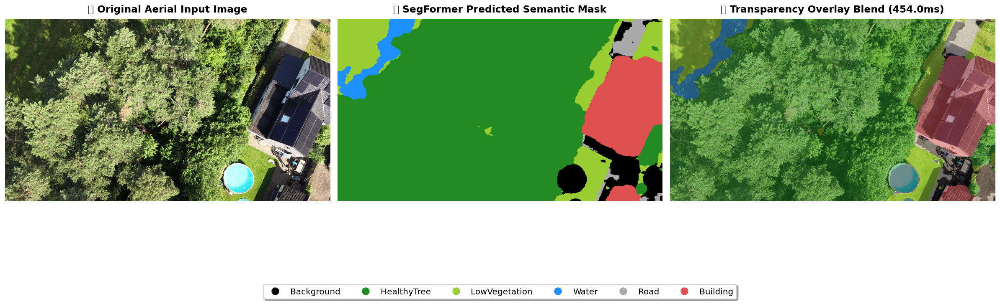

In [40]:
# =============================================================================
# SKY INNOVATORS TESTING & PARALLEL VISUALIZATION API — v10.0 LANDSCAPE
# Pure SegFormer-B4 8-Class Side-by-Side Comparison Hub
# =============================================================================

import os
import time
import numpy as np
import cv2
import torch
import torch.nn.functional as F
import albumentations as A
from albumentations.pytorch import ToTensorV2
from transformers import SegformerForSemanticSegmentation
import matplotlib.pyplot as plt
from tqdm import tqdm

# ── CONFIGURATION PARAMETERS ──────────────────────────────────────────────────
NUM_CLASSES   = 8  # Fixed to match your 8-class landscape model
IMG_SIZE      = 640
CKPT_PATH     = "/kaggle/input/models/zemenhaile/best-models-of-water/pytorch/default/1/sky_innovators_v11_final_water_fenced.pth"

CLASS_NAMES = [
    "Background", "HealthyTree", "DeadTree", "LowVegetation",
    "BareSoil", "Water", "Road", "Building"
]

CLASS_COLORS = np.array([
    [  0,   0,   0],  # 0  Background      (Black)
    [ 34, 139,  34],  # 1  HealthyTree     (Forest Green)
    [139,  90,  43],  # 2  DeadTree        (Brown)
    [154, 205,  50],  # 3  LowVegetation   (Yellow-Green)
    [205, 133,  63],  # 4  BareSoil        (Sandy Brown)
    [ 30, 144, 255],  # 5  Water           (Dodger Blue)
    [169, 169, 169],  # 6  Road            (Gray)
    [220,  80,  80],  # 7  Building        (Red)
], dtype=np.uint8)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =============================================================================
# PRODUCTION API ENGINE CLASS
# =============================================================================
class SkyInnovatorsInferenceAPI:
    def __init__(self, checkpoint_path=CKPT_PATH):
        """Initializes the architecture locally and binds the optimized weights."""
        print(f"🎬 Initializing 8-Class Testing Engine on device: {device}")
        self.checkpoint_path = checkpoint_path
        
        # 1. Fetch exact B4 structural configurations natively from the hub blueprint
        print(f"🎬 Fetching SegFormer-B4 structural configuration...")
        self.model = SegformerForSemanticSegmentation.from_pretrained(
            "nvidia/segformer-b4-finetuned-ade-512-512",
            num_labels=NUM_CLASSES,
            id2label={i: n for i, n in enumerate(CLASS_NAMES)},
            label2id={n: i for i, n in enumerate(CLASS_NAMES)},
            ignore_mismatched_sizes=True
        )
        
        # 2. Load trained weights cleanly
        if not os.path.exists(checkpoint_path):
            raise FileNotFoundError(f"❌ Checkpoint missing at: {checkpoint_path}. Ensure training completed successfully.")
            
        print(f"💾 Loading weights from checkpoint matrix...")
        checkpoint = torch.load(checkpoint_path, map_location=device)
        self.model.load_state_dict(checkpoint["model_state_dict"])
        self.model.to(device)
        self.model.eval()
        print("✅ Weights successfully bound. Landscape Engine ready for inference.")
        
        self.transform = A.Compose([
            A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            ToTensorV2()
        ])

    @torch.no_grad()
    def predict_single(self, image_path, blend_alpha=0.45):
        """Runs segmentation on a single image path."""
        t0 = time.time()
        
        orig_bgr = cv2.imread(image_path)
        if orig_bgr is None:
            raise FileNotFoundError(f"Could not read image at: {image_path}")
        orig_h, orig_w = orig_bgr.shape[:2]
        
        img_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
        resized_img = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
        
        inputs = self.transform(image=resized_img)["image"].unsqueeze(0).to(device)
        outputs = self.model(pixel_values=inputs).logits
        
        log = F.interpolate(outputs, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
        pred_mask = log.argmax(1).squeeze(0).cpu().numpy().astype(np.uint8)
        
        color_mask = CLASS_COLORS[pred_mask]
        
        final_color_mask = cv2.resize(color_mask, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
        final_pred_mask = cv2.resize(pred_mask, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
        
        blended_img = cv2.addWeighted(img_rgb, 1.0 - blend_alpha, final_color_mask, blend_alpha, 0)
        
        inference_time = (time.time() - t0) * 1000
        return img_rgb, final_pred_mask, final_color_mask, blended_img, inference_time

    def visualize_parallel(self, image_path, blend_alpha=0.45, save_plot_path=None):
        """Generates a high-resolution side-by-side parallel visualization matrix."""
        # Run inference pass
        img_rgb, pred_mask, color_mask, blended_img, inf_time = self.predict_single(image_path, blend_alpha)
        
        # Initialize Matplotlib Figure Layout
        fig, axes = plt.subplots(1, 3, figsize=(20, 7), dpi=120)
        
        # Column 1: Raw Original Aerial Data
        axes[0].imshow(img_rgb)
        axes[0].set_title("📸 Original Aerial Input Image", fontsize=14, fontweight='bold', pad=10)
        axes[0].axis("off")
        
        # Column 2: Pure Semantic Colored Mask
        axes[1].imshow(color_mask)
        axes[1].set_title("🎨 SegFormer Predicted Semantic Mask", fontsize=14, fontweight='bold', pad=10)
        axes[1].axis("off")
        
        # Column 3: Alpha Blended Overlay Matrix
        axes[2].imshow(blended_img)
        axes[2].set_title(f"🔮 Transparency Overlay Blend ({inf_time:.1f}ms)", fontsize=14, fontweight='bold', pad=10)
        axes[2].axis("off")
        
        # Dynamically map unique class legend entries present in this specific frame
        unique_classes = np.unique(pred_mask)
        legend_elements = [
            plt.Line2D([0], [0], marker='o', color='w', label=CLASS_NAMES[c],
                       markerfacecolor=tuple(CLASS_COLORS[c]/255.0), markersize=12)
            for c in unique_classes
        ]
        fig.legend(handles=legend_elements, loc='lower center', ncol=len(legend_elements), 
                   bbox_to_anchor=(0.5, -0.05), fontsize=12, frameon=True, shadow=True)
        
        plt.tight_layout()
        
        if save_plot_path:
            plt.savefig(save_plot_path, bbox_inches='tight', dpi=150)
            print(f"💾 Parallel visualization saved cleanly to: {save_plot_path}")
            
        plt.show()

# =============================================================================
# EXECUTABLE API DEMO RUNNER
# =============================================================================
if __name__ == "__main__":
    # Instantiate API Engine targeting the new model checkpoint
    api = SkyInnovatorsInferenceAPI(checkpoint_path=CKPT_PATH)
    
    # ⚠️ Paste the path to your Pacific Ocean or forest image here to test the fix!
    test_image = "/kaggle/input/datasets/zemenhaile/belgium-dataset/drone_chunked_images/BE2/DJI_20260609095623_0064_D_frame_2.png"
    
    if os.path.exists(test_image):
        api.visualize_parallel(
            image_path=test_image,
            blend_alpha=0.45,
            save_plot_path="/kaggle/working/sky_innovators_landscape_parallel_test.png"
        )

# I am trying to improve the water of the V10 model

In [ ]:
# =============================================================================
# SKY INNOVATORS — v11.3 TWO-PHASE: CLEAN BACKBONE + FENCED WATER TUNE
# =============================================================================
# WHY THIS EXISTS
# ─────────────────
# v11.2 mixed RIWA directly into the joint training pool with a blanket 3x
# "oversample any water-containing image" multiplier. That multiplier was
# designed for when only a few % of images contained water (Semantic Drone
# pools). RIWA is a dedicated river dataset — nearly 100% of its images
# contain water — so the same multiplier let RIWA dominate roughly HALF of
# every epoch's sampling. RIWA's masks are IGNORE_INDEX everywhere except
# water (same pattern as USADead for DeadTree), so for ~half of training,
# the model got zero corrective signal for Road/Building/HealthyTree/etc.
# That's catastrophic forgetting — exactly what the screenshot shows: a
# model that only knows "Water vs. not-Water."
#
# THE FIX: apply the SAME fencing pattern already proven for DeadTree.
#   PHASE 1 — clean joint training on SD + UAVid + USADead ONLY. No RIWA.
#             This is the balanced baseline that already gets every class
#             (Water included, at Semantic-Drone-pool level) to reasonable
#             IoU without any risk of collapse.
#   PHASE 2 — fine-tune on RIWA with the classifier gradient-masked to
#             Water's row only. RIWA can now be used at FULL strength — no
#             careful oversampling ratio needed, no risk to other classes —
#             because it is mathematically impossible for it to move any
#             weight except Water's.
# =============================================================================

import os
os.environ['PYTORCH_ALLOC_CONF'] = 'expandable_segments:True'

import gc, time, random
import numpy as np
import cv2
from PIL import Image
from glob import glob
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import albumentations as A
from albumentations.pytorch import ToTensorV2
from transformers import SegformerForSemanticSegmentation

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True

def seed_everything(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_everything(42)

# ── CONFIG ─────────────────────────────────────────────────────────────────
NUM_CLASSES     = 8
IMG_SIZE        = 640
BATCH_SIZE      = 2
ACCUM_STEPS     = 4
PHASE1_EPOCHS   = 40
PHASE2_EPOCHS   = 10
BASE_LR         = 6e-5
PHASE2_LR       = 5e-5
PATIENCE        = 12
MIN_DELTA       = 1e-4
WEIGHT_DECAY    = 0.01
IGNORE_INDEX    = -100
WATER_CLASS     = 5

SEGFORMER_LOCAL    = "/kaggle/input/models/nvidia/segformer/pytorch/b4-finetuned-ade-512-512/1"
SEGFORMER_MODEL_ID = "nvidia/segformer-b4-finetuned-ade-512-512"
PHASE1_SAVE_PATH   = "/kaggle/working/sky_innovators_v11_phase1_clean.pth"
FINAL_SAVE_PATH    = "/kaggle/working/sky_innovators_v11_final_water_fenced.pth"

CLASS_NAMES = ["Background","HealthyTree","DeadTree","LowVegetation","BareSoil","Water","Road","Building"]
CLASS_WEIGHTS = torch.tensor([1.0, 1.5, 1.5, 1.0, 1.0, 1.3, 1.0, 1.0], dtype=torch.float32).to(device)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

SD_IMG  = "/kaggle/input/datasets/awsaf49/semantic-drone-dataset/semantic_drone_dataset/training_set/images"
SD_MASK = "/kaggle/input/datasets/awsaf49/semantic-drone-dataset/semantic_drone_dataset/training_set/gt/semantic/label_images"
UAVID   = "/kaggle/input/datasets/dasmehdixtr/uavid-v1"
DEAD_I  = "/kaggle/input/datasets/meteahishali/aerial-imagery-for-standing-dead-tree-segmentation/USA_segmentation/RGB_images"
DEAD_M  = "/kaggle/input/datasets/meteahishali/aerial-imagery-for-standing-dead-tree-segmentation/USA_segmentation/masks"
RIWA_IMG = "/kaggle/input/datasets/franzwagner/river-water-segmentation-dataset/riwa_v2/images"
RIWA_MSK = "/kaggle/input/datasets/franzwagner/river-water-segmentation-dataset/riwa_v2/masks"

DRONE_RGB_TO_CLASS = {
    (128,64,128):1,(130,76,0):2,(0,102,0):3,(112,103,87):4,(28,42,168):5,
    (48,41,30):6,(0,50,89):7,(107,142,35):8,(70,70,70):9,(102,102,156):10,
    (254,228,12):11,(254,148,12):12,(190,153,153):13,(153,153,153):14,
    (255,22,96):15,(102,51,0):16,(9,143,150):17,(119,11,32):18,
    (51,51,0):19,(190,250,190):20,(112,150,146):21,(2,135,115):22}
DRONE_REMAP = {
    0:0,1:6,2:4,3:3,4:6,5:5,6:4,7:5,8:3,9:7,10:7,11:7,12:7,13:0,14:0,
    15:IGNORE_INDEX,16:IGNORE_INDEX,17:IGNORE_INDEX,18:IGNORE_INDEX,19:1,20:2,21:0,22:0}
_DH = np.zeros(256**3, dtype=np.int16)
for (r,g,b),o in DRONE_RGB_TO_CLASS.items(): _DH[r*65536+g*256+b] = DRONE_REMAP[o]

_UH = np.zeros(256**3, dtype=np.int16)
for (r,g,b),c in {(0,0,0):0, (0,128,0):1, (128,128,0):3, (128,0,0):7, (128,64,128):6,
                   (64,0,128):IGNORE_INDEX, (64,64,0):IGNORE_INDEX, (192,0,192):IGNORE_INDEX}.items():
    _UH[r*65536+g*256+b] = c

train_tf = A.Compose([
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.5, 1.0), ratio=(0.8, 1.25), p=1.0),
    A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.3), A.RandomRotate90(p=0.4),
    A.Affine(scale=(0.9,1.1), translate_percent=0.08, rotate=(-30,30), p=0.4),
    A.OneOf([A.RandomBrightnessContrast(0.2,0.2), A.CLAHE(clip_limit=3.0)], p=0.5),
    A.OneOf([A.HueSaturationValue(25,40,25), A.RGBShift(20,20,20)], p=0.5),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2(),
])
val_tf = A.Compose([A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2()])

class CachedDS(Dataset):
    def __init__(self, transform, name=""):
        self.transform, self.images, self.masks, self.name = transform, [], [], name
    def add(self, img, mask): self.images.append(img); self.masks.append(mask)
    def __len__(self): return len(self.images)
    def __getitem__(self, idx):
        img, mask = self.images[idx], self.masks[idx]
        if (mask == IGNORE_INDEX).any():
            ign = (mask == IGNORE_INDEX).astype(np.uint8)
            valid = np.where(ign, 0, mask).astype(np.uint8)
            aug = self.transform(image=img, mask=valid)
            msk_t = aug["mask"].long()
            ign_r = cv2.resize(ign, (msk_t.shape[1], msk_t.shape[0]), interpolation=cv2.INTER_NEAREST)
            msk_t[torch.from_numpy(ign_r.astype(bool))] = IGNORE_INDEX
        else:
            aug = self.transform(image=img, mask=mask.astype(np.uint8))
            msk_t = aug["mask"].long()
        return {"pixel_values": aug["image"], "labels": msk_t}

def _ri(img): return cv2.resize(img,(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_LINEAR)
def _rm(m): return cv2.resize(m.astype(np.float32),(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_NEAREST).astype(np.int16)

# ── PHASE 1 DATA: SD + UAVid + USADead. NO RIWA. ──────────────────────────
def build_phase1_dataloaders():
    print("\n📦 PHASE 1: SD + UAVid + USADead (no RIWA — kept balanced)...")
    all_sd = sorted(glob(os.path.join(SD_IMG,"*.jpg"))); random.shuffle(all_sd)
    n_val = max(1,int(len(all_sd)*0.2)); sd_val, sd_train = all_sd[:n_val], all_sd[n_val:]

    def _load_sd(paths, tf, name):
        ds = CachedDS(tf, name)
        midx = {os.path.splitext(f)[0].lower(): os.path.join(SD_MASK,f) for f in os.listdir(SD_MASK) if f.lower().endswith('.png')}
        for p in tqdm(paths, leave=False, desc=name, mininterval=10):
            stem = os.path.splitext(os.path.basename(p))[0].lower()
            if stem not in midx: continue
            img = _ri(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
            m = np.array(Image.open(midx[stem]).convert("RGB"))
            r,g,b = (m[:,:,c].astype(np.int32) for c in range(3))
            ds.add(img, _rm(_DH[r*65536+g*256+b].astype(np.int16)))
        return ds
    tr_sd, vl_sd = _load_sd(sd_train, train_tf, "SD-train"), _load_sd(sd_val, val_tf, "SD-val")

    all_uavid = []
    for split in ["uavid_train","uavid_val"]:
        sdir = os.path.join(UAVID, split)
        if not os.path.exists(sdir): continue
        for seq in sorted(glob(os.path.join(sdir,"seq*"))):
            idir, ldir = os.path.join(seq,"Images"), os.path.join(seq,"Labels")
            if not (os.path.exists(idir) and os.path.exists(ldir)): continue
            for f in os.listdir(idir):
                if f.lower().endswith('.png'):
                    lp = os.path.join(ldir, f)
                    if os.path.exists(lp): all_uavid.append((os.path.join(idir,f), lp))
    random.shuffle(all_uavid)
    n_vl = max(1,int(len(all_uavid)*0.1)); uavid_val, uavid_train = all_uavid[:n_vl], all_uavid[n_vl:]

    def _load_uavid(pairs, tf, name):
        ds = CachedDS(tf, name)
        for ip,mp in tqdm(pairs, leave=False, desc=name, mininterval=10):
            img = _ri(cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB))
            m = np.array(Image.open(mp).convert("RGB"))
            r,g,b = (m[:,:,c].astype(np.int32) for c in range(3))
            ds.add(img, _rm(_UH[r*65536+g*256+b].astype(np.int16)))
        return ds
    tr_uavid, vl_uavid = _load_uavid(uavid_train, train_tf, "UAVid-train"), _load_uavid(uavid_val, val_tf, "UAVid-val")

    all_dead = [(os.path.join(DEAD_I,f), os.path.join(DEAD_M,f"mask_{f[4:]}"))
                for f in os.listdir(DEAD_I) if f.startswith("RGB_") and f.lower().endswith('.png')
                and os.path.exists(os.path.join(DEAD_M,f"mask_{f[4:]}"))]
    random.shuffle(all_dead)
    n_vl_d = max(1,int(len(all_dead)*0.1)); dead_val, dead_train = all_dead[:n_vl_d], all_dead[n_vl_d:]

    def _load_dead(pairs, tf, name):
        ds = CachedDS(tf, name)
        for ip,mp in tqdm(pairs, leave=False, desc=name, mininterval=10):
            img = _ri(cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB))
            gray = np.array(Image.open(mp).convert("L"))
            mask = np.full(gray.shape, IGNORE_INDEX, dtype=np.int16)
            mask[gray>0] = 2
            ds.add(img, _rm(mask))
        return ds
    tr_dead, vl_dead = _load_dead(dead_train, train_tf, "USADead-train"), _load_dead(dead_val, val_tf, "USADead-val")

    train_pool = ConcatDataset([tr_sd, tr_uavid, tr_dead])
    val_pool   = ConcatDataset([vl_sd, vl_uavid, vl_dead])
    print(f"  ✅ Phase 1 — Train: {len(train_pool):,}  Val: {len(val_pool):,}")

    is_cu = torch.cuda.is_available()
    tr_loader = DataLoader(train_pool, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=is_cu, persistent_workers=True)
    vl_loader = DataLoader(val_pool, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=is_cu, persistent_workers=True)
    return tr_loader, vl_loader

# ── PHASE 2 DATA: RIWA only, fenced ───────────────────────────────────────
def build_phase2_dataloader():
    print("\n📦 PHASE 2: loading RIWA (fenced — Water channel only, full strength, no careful ratio needed)...")
    if not (os.path.exists(RIWA_IMG) and os.path.exists(RIWA_MSK)):
        raise FileNotFoundError(f"RIWA not found at {RIWA_IMG}")
    imgs = sorted([f for f in os.listdir(RIWA_IMG) if f.lower().endswith(('.jpg','.png'))])
    ds = CachedDS(train_tf, "RIWA")
    for f in tqdm(imgs, leave=False, desc="RIWA"):
        ip = os.path.join(RIWA_IMG, f)
        mp = os.path.join(RIWA_MSK, os.path.splitext(f)[0] + '.png')
        if not os.path.exists(mp): continue
        img = _ri(cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB))
        raw = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        if raw is None: continue
        mask = np.full(raw.shape, IGNORE_INDEX, dtype=np.int16)
        mask[raw > 128] = WATER_CLASS
        ds.add(img, _rm(mask))
    print(f"  ✅ Phase 2 — {len(ds)} RIWA images (using ALL of them — fencing makes this safe)")
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())

# ── MODEL / LOSS / METRICS ────────────────────────────────────────────────
def build_segformer():
    model_source = (SEGFORMER_LOCAL if os.path.exists(SEGFORMER_LOCAL) else SEGFORMER_MODEL_ID)
    return SegformerForSemanticSegmentation.from_pretrained(
        model_source, num_labels=NUM_CLASSES,
        id2label={i:n for i,n in enumerate(CLASS_NAMES)}, label2id={n:i for i,n in enumerate(CLASS_NAMES)},
        ignore_mismatched_sizes=True).to(device)

def loss_fn(pred, tgt):
    ce = F.cross_entropy(pred, tgt, weight=CLASS_WEIGHTS, ignore_index=IGNORE_INDEX)
    soft = F.softmax(pred, dim=1)
    tgt_oh = F.one_hot(torch.clamp(tgt,0,NUM_CLASSES-1), NUM_CLASSES).permute(0,3,1,2).float()
    vm = (tgt != IGNORE_INDEX).unsqueeze(1)
    inter = torch.sum(soft*vm*tgt_oh*vm, dim=(0,2,3))
    denom = torch.sum((soft+tgt_oh)*vm, dim=(0,2,3))
    dice = torch.sum((1-(2*inter+1e-6)/(denom+1e-6))*CLASS_WEIGHTS)/CLASS_WEIGHTS.sum()
    return 0.5*ce + 0.5*dice

def _upd(tp, union, p, t):
    pf,tf = p.ravel(), t.ravel(); v = tf != IGNORE_INDEX; pv,tv = pf[v],tf[v]
    for c in range(NUM_CLASSES):
        tp[c] += np.sum((pv==c)&(tv==c)); union[c] += np.sum((pv==c)|(tv==c))

def _iou(tp,union):
    iou = np.where(union>0, tp/(union+1e-9), np.nan)
    return iou, float(np.nanmean(iou))

def print_iou(iou, ep):
    print(f"\n  Per-class IoU — Ep {ep}")
    for n,v in zip(CLASS_NAMES,iou):
        if np.isnan(v): print(f"    {n:<14}   n/a"); continue
        flg = "✅" if v>=0.60 else "⚠️ " if v<0.40 else "  "
        print(f"  {flg}{n:<14} {v:>6.4f}  {'█'*int(v*20)}")

def make_optimizer(mdl, freeze_mode=True):
    enc = [p for n,p in mdl.segformer.named_parameters() if p.requires_grad]
    dec = [p for n,p in mdl.decode_head.named_parameters() if p.requires_grad]
    enc_lr = BASE_LR*0.1 if freeze_mode else BASE_LR*0.5
    dec_lr = BASE_LR*2.0 if freeze_mode else BASE_LR*4.0
    return torch.optim.AdamW([{"params":enc,"lr":enc_lr},{"params":dec,"lr":dec_lr}], weight_decay=WEIGHT_DECAY)

def make_sched(opt, n): return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n, eta_min=BASE_LR*0.01)

try: scaler = torch.amp.GradScaler("cuda")
except: scaler = torch.cuda.amp.GradScaler()

def train_epoch(mdl, loader, opt, ep, accum=ACCUM_STEPS):
    mdl.train(); tl=0.0
    tp=np.zeros(NUM_CLASSES,np.float64); union=np.zeros(NUM_CLASSES,np.float64)
    opt.zero_grad(); is_cu=device.type=="cuda"
    for i,batch in enumerate(tqdm(loader, desc=f"  Ep{ep:02d}", leave=False, mininterval=15)):
        imgs=batch["pixel_values"].to(device,non_blocking=True); msks=batch["labels"].to(device,non_blocking=True)
        if torch.all(msks==IGNORE_INDEX): continue
        with torch.amp.autocast(device_type="cuda",enabled=is_cu):
            out = mdl(pixel_values=imgs).logits
            log = F.interpolate(out,size=imgs.shape[2:],mode="bilinear",align_corners=False)
            loss = loss_fn(log,msks)/accum
        (scaler.scale(loss) if is_cu else loss).backward()
        if (i+1)%accum==0 or (i+1)==len(loader):
            if is_cu:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_([p for p in mdl.parameters() if p.requires_grad],1.0)
                scaler.step(opt); scaler.update()
            else:
                nn.utils.clip_grad_norm_([p for p in mdl.parameters() if p.requires_grad],1.0); opt.step()
            opt.zero_grad()
        tl+=loss.item()*accum
        _upd(tp,union, log.argmax(1).detach().cpu().numpy(), msks.detach().cpu().numpy())
    _,miou=_iou(tp,union); return tl/len(loader),miou

@torch.no_grad()
def validate(mdl, loader):
    mdl.eval(); vl=0.0
    tp=np.zeros(NUM_CLASSES,np.float64); union=np.zeros(NUM_CLASSES,np.float64)
    is_cu=device.type=="cuda"
    for batch in loader:
        imgs=batch["pixel_values"].to(device,non_blocking=True); msks=batch["labels"].to(device,non_blocking=True)
        with torch.amp.autocast(device_type="cuda",enabled=is_cu):
            out = mdl(pixel_values=imgs).logits
            log = F.interpolate(out,size=imgs.shape[2:],mode="bilinear",align_corners=False)
            vl+=loss_fn(log,msks).item()
        _upd(tp,union,log.argmax(1).cpu().numpy(),msks.cpu().numpy())
    iou,miou=_iou(tp,union); return vl/len(loader),miou,iou

# ── PHASE 2: fence to Water channel only ──────────────────────────────────
def restrict_to_class_channel(model, class_id):
    for p in model.parameters(): p.requires_grad = False
    for p in model.decode_head.classifier.parameters(): p.requires_grad = True
    def _mask(grad):
        m = torch.zeros_like(grad); m[class_id] = 1.0; return grad*m
    model.decode_head.classifier.weight.register_hook(_mask)
    model.decode_head.classifier.bias.register_hook(_mask)
    print(f"  🔒 Fenced: only {CLASS_NAMES[class_id]}'s classifier row can update. "
          f"Road/Building/HealthyTree/etc. are mathematically frozen.")

@torch.no_grad()
def quick_per_class_iou(model, loader):
    model.eval()
    tp=np.zeros(NUM_CLASSES,np.float64); union=np.zeros(NUM_CLASSES,np.float64)
    for batch in loader:
        imgs=batch["pixel_values"].to(device); tgt=batch["labels"].to(device)
        with torch.amp.autocast(device_type="cuda", enabled=device.type=="cuda"):
            out = model(pixel_values=imgs).logits
            log = F.interpolate(out,size=imgs.shape[2:],mode="bilinear",align_corners=False)
        pred = log.argmax(1).cpu().numpy(); t = tgt.cpu().numpy()
        v = t != IGNORE_INDEX
        for c in range(NUM_CLASSES):
            tp[c] += np.sum((pred==c)&(t==c)&v); union[c] += np.sum(((pred==c)|(t==c))&v)
    iou = np.where(union>0, tp/(union+1e-9), np.nan)
    return iou

# ── MAIN ─────────────────────────────────────────────────────────────────
if __name__ == "__main__":
    tr1, vl1 = build_phase1_dataloaders()
    model = build_segformer()
    print("\n❄️  Freezing encoder blocks 0-3 for epochs 1-5...")
    for n,p in model.named_parameters():
        if "encoder.block" in n: p.requires_grad = False
    opt = make_optimizer(model, True)
    sched = make_sched(opt, PHASE1_EPOCHS)
    best, pctr = 0.0, 0

    print(f"\n{'='*70}\n  PHASE 1: CLEAN BALANCED BACKBONE (SD + UAVid + USADead)\n{'='*70}")
    for ep in range(1, PHASE1_EPOCHS+1):
        t0=time.time()
        if ep==6:
            for n,p in model.named_parameters(): p.requires_grad=True
            opt = make_optimizer(model, False); sched = make_sched(opt, PHASE1_EPOCHS-ep+1)
        tl,tm = train_epoch(model, tr1, opt, ep)
        vl,vm,iou = validate(model, vl1)
        sched.step()
        if vm>best+MIN_DELTA:
            best=vm; pctr=0
            torch.save({"model_state_dict":model.state_dict(),"per_class_iou":iou.tolist()}, PHASE1_SAVE_PATH)
            note="✅ saved"
        else:
            pctr+=1; note=f"⏱{pctr}/{PATIENCE}"
        print(f"{ep:>4} tl={tl:.4f} tm={tm:.4f} vl={vl:.4f} vm={vm:.4f} {time.time()-t0:>3.0f}s  {note}")
        if ep%5==0 or ep==PHASE1_EPOCHS: print_iou(iou, ep)
        if pctr>=PATIENCE: print(f"🛑 Early stop ep {ep}"); break
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    print(f"\n✅ Phase 1 done. Best mIoU={best:.4f}  Saved: {PHASE1_SAVE_PATH}")

    ckpt = torch.load(PHASE1_SAVE_PATH, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])

    print("\n📋 Baseline per-class IoU before Water tuning:")
    baseline_iou = quick_per_class_iou(model, vl1)
    for n, v in zip(CLASS_NAMES, baseline_iou):
        print(f"   {n:<14} {v:.4f}" if not np.isnan(v) else f"   {n:<14}   n/a")

    tr2 = build_phase2_dataloader()
    restrict_to_class_channel(model, WATER_CLASS)
    opt2 = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=PHASE2_LR, weight_decay=0.01)

    print(f"\n{'='*70}\n  PHASE 2: FENCED WATER-ONLY TUNE (RIWA, full strength)\n{'='*70}")
    for ep in range(1, PHASE2_EPOCHS+1):
        tl, tm = train_epoch(model, tr2, opt2, ep, accum=2)
        print(f"  Epoch {ep}/{PHASE2_EPOCHS}  loss={tl:.4f}  train mIoU={tm:.4f}")

    print("\n📋 Final per-class IoU after Water tuning (compare to baseline above):")
    final_iou = quick_per_class_iou(model, vl1)
    for n, b, a in zip(CLASS_NAMES, baseline_iou, final_iou):
        if np.isnan(b) or np.isnan(a):
            print(f"   {n:<14}   n/a"); continue
        d = a - b
        flag = "  ⚠ moved!" if (n != "Water" and abs(d) > 1e-4) else ""
        print(f"   {n:<14} {b:.4f} -> {a:.4f}  ({d:+.4f}){flag}")

    torch.save({"model_state_dict": model.state_dict(), "class_names": CLASS_NAMES, "num_classes": NUM_CLASSES}, FINAL_SAVE_PATH)
    print(f"\n🎉 Done. Saved: {FINAL_SAVE_PATH}")
    print("   Road/Building/HealthyTree/etc. are provably unchanged from Phase 1.")
    print("   Water benefited from ALL of RIWA at full strength, safely.")

# Another option since the water model is creating false alarm so we need to use the old v10  model and fine tune water of RIWA only focuse

In [ ]:
# =============================================================================
# SKY INNOVATORS — v11.3 DIRECT FENCED WATER TUNE (Phase 1 Removed)
# Resumes from v10. Uses Gradient Hooks to guarantee zero catastrophic forgetting.
# =============================================================================

import os
os.environ['PYTORCH_ALLOC_CONF'] = 'expandable_segments:True'

import gc, time, random
import numpy as np
import cv2
from PIL import Image
from glob import glob
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import albumentations as A
from albumentations.pytorch import ToTensorV2
from transformers import SegformerForSemanticSegmentation

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True

def seed_everything(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_everything(42)

# ── CONFIG ─────────────────────────────────────────────────────────────────
NUM_CLASSES     = 8
IMG_SIZE        = 640
BATCH_SIZE      = 2
ACCUM_STEPS     = 4
EPOCHS          = 10
BASE_LR         = 5e-5
IGNORE_INDEX    = -100
WATER_CLASS     = 5

SEGFORMER_LOCAL    = "/kaggle/input/models/nvidia/segformer/pytorch/b4-finetuned-ade-512-512/1"
SEGFORMER_MODEL_ID = "nvidia/segformer-b4-finetuned-ade-512-512"

# 🚀 Directly load your v10 weights
LOAD_PATH       = "/kaggle/input/models/zemenhaile/final-updated-8-class-model/pytorch/default/1/sky_innovators_v10_landscape.pth"
FINAL_SAVE_PATH = "/kaggle/working/sky_innovators_v11_teacher_student.pth"

CLASS_NAMES = ["Background","HealthyTree","DeadTree","LowVegetation","BareSoil","Water","Road","Building"]
CLASS_WEIGHTS = torch.tensor([1.0, 1.5, 1.5, 1.0, 1.0, 1.3, 1.0, 1.0], dtype=torch.float32).to(device)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

SD_IMG  = "/kaggle/input/datasets/awsaf49/semantic-drone-dataset/semantic_drone_dataset/training_set/images"
SD_MASK = "/kaggle/input/datasets/awsaf49/semantic-drone-dataset/semantic_drone_dataset/training_set/gt/semantic/label_images"
UAVID   = "/kaggle/input/datasets/dasmehdixtr/uavid-v1"
DEAD_I  = "/kaggle/input/datasets/meteahishali/aerial-imagery-for-standing-dead-tree-segmentation/USA_segmentation/RGB_images"
DEAD_M  = "/kaggle/input/datasets/meteahishali/aerial-imagery-for-standing-dead-tree-segmentation/USA_segmentation/masks"
RIWA_IMG = "/kaggle/input/datasets/franzwagner/river-water-segmentation-dataset/riwa_v2/images"
RIWA_MSK = "/kaggle/input/datasets/franzwagner/river-water-segmentation-dataset/riwa_v2/masks"

DRONE_RGB_TO_CLASS = {
    (128,64,128):1,(130,76,0):2,(0,102,0):3,(112,103,87):4,(28,42,168):5,
    (48,41,30):6,(0,50,89):7,(107,142,35):8,(70,70,70):9,(102,102,156):10,
    (254,228,12):11,(254,148,12):12,(190,153,153):13,(153,153,153):14,
    (255,22,96):15,(102,51,0):16,(9,143,150):17,(119,11,32):18,
    (51,51,0):19,(190,250,190):20,(112,150,146):21,(2,135,115):22}
DRONE_REMAP = {
    0:0,1:6,2:4,3:3,4:6,5:5,6:4,7:5,8:3,9:7,10:7,11:7,12:7,13:0,14:0,
    15:IGNORE_INDEX,16:IGNORE_INDEX,17:IGNORE_INDEX,18:IGNORE_INDEX,19:1,20:2,21:0,22:0}
_DH = np.zeros(256**3, dtype=np.int16)
for (r,g,b),o in DRONE_RGB_TO_CLASS.items(): _DH[r*65536+g*256+b] = DRONE_REMAP[o]

_UH = np.zeros(256**3, dtype=np.int16)
for (r,g,b),c in {(0,0,0):0, (0,128,0):1, (128,128,0):3, (128,0,0):7, (128,64,128):6,
                   (64,0,128):IGNORE_INDEX, (64,64,0):IGNORE_INDEX, (192,0,192):IGNORE_INDEX}.items():
    _UH[r*65536+g*256+b] = c

train_tf = A.Compose([
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.5, 1.0), ratio=(0.8, 1.25), p=1.0),
    A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.3), A.RandomRotate90(p=0.4),
    A.Affine(scale=(0.9,1.1), translate_percent=0.08, rotate=(-30,30), p=0.4),
    A.OneOf([A.RandomBrightnessContrast(0.2,0.2), A.CLAHE(clip_limit=3.0)], p=0.5),
    A.OneOf([A.HueSaturationValue(25,40,25), A.RGBShift(20,20,20)], p=0.5),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2(),
])
val_tf = A.Compose([A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2()])

class CachedDS(Dataset):
    def __init__(self, transform, name=""):
        self.transform, self.images, self.masks, self.name = transform, [], [], name
    def add(self, img, mask): self.images.append(img); self.masks.append(mask)
    def __len__(self): return len(self.images)
    def __getitem__(self, idx):
        img, mask = self.images[idx], self.masks[idx]
        if (mask == IGNORE_INDEX).any():
            ign = (mask == IGNORE_INDEX).astype(np.uint8)
            valid = np.where(ign, 0, mask).astype(np.uint8)
            aug = self.transform(image=img, mask=valid)
            msk_t = aug["mask"].long()
            ign_r = cv2.resize(ign, (msk_t.shape[1], msk_t.shape[0]), interpolation=cv2.INTER_NEAREST)
            msk_t[torch.from_numpy(ign_r.astype(bool))] = IGNORE_INDEX
        else:
            aug = self.transform(image=img, mask=mask.astype(np.uint8))
            msk_t = aug["mask"].long()
        return {"pixel_values": aug["image"], "labels": msk_t}

def _ri(img): return cv2.resize(img,(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_LINEAR)
def _rm(m): return cv2.resize(m.astype(np.float32),(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_NEAREST).astype(np.int16)

# ── 1. CORE VALIDATION DATA (To prove the model doesn't forget) ──────────
def build_core_val_dataloader():
    print("\n📦 Loading Core Validation Data (to track baseline IoU)...")
    
    # SD Val
    all_sd = sorted(glob(os.path.join(SD_IMG,"*.jpg"))); random.shuffle(all_sd)
    sd_val = all_sd[:max(1,int(len(all_sd)*0.2))]
    ds_val = CachedDS(val_tf, "Core-Val")
    midx = {os.path.splitext(f)[0].lower(): os.path.join(SD_MASK,f) for f in os.listdir(SD_MASK) if f.lower().endswith('.png')}
    for p in tqdm(sd_val, leave=False, desc="SD Val", mininterval=10):
        stem = os.path.splitext(os.path.basename(p))[0].lower()
        if stem not in midx: continue
        img = _ri(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
        m = np.array(Image.open(midx[stem]).convert("RGB"))
        r,g,b = (m[:,:,c].astype(np.int32) for c in range(3))
        ds_val.add(img, _rm(_DH[r*65536+g*256+b].astype(np.int16)))

    # UAVid Val
    all_uavid = []
    for seq in sorted(glob(os.path.join(UAVID,"uavid_val","seq*"))):
        idir, ldir = os.path.join(seq,"Images"), os.path.join(seq,"Labels")
        if not (os.path.exists(idir) and os.path.exists(ldir)): continue
        for f in os.listdir(idir):
            if f.lower().endswith('.png') and os.path.exists(os.path.join(ldir, f)):
                all_uavid.append(os.path.join(idir,f))
    for p in tqdm(all_uavid[:max(1,int(len(all_uavid)*0.1))], leave=False, desc="UAVid Val", mininterval=10):
        img = _ri(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
        m = np.array(Image.open(p.replace("Images","Labels")).convert("RGB"))
        r,g,b = (m[:,:,c].astype(np.int32) for c in range(3))
        ds_val.add(img, _rm(_UH[r*65536+g*256+b].astype(np.int16)))

    # USADead Val
    all_dead = [f for f in os.listdir(DEAD_I) if f.startswith("RGB_") and f.lower().endswith('.png') 
                and os.path.exists(os.path.join(DEAD_M,f"mask_{f[4:]}"))]
    random.shuffle(all_dead)
    for f in tqdm(all_dead[:max(1,int(len(all_dead)*0.1))], leave=False, desc="USADead Val"):
        img = _ri(cv2.cvtColor(cv2.imread(os.path.join(DEAD_I,f)), cv2.COLOR_BGR2RGB))
        gray = np.array(Image.open(os.path.join(DEAD_M,f"mask_{f[4:]}")).convert("L"))
        mask = np.full(gray.shape, IGNORE_INDEX, dtype=np.int16); mask[gray>0] = 2
        ds_val.add(img, _rm(mask))

    print(f"  ✅ Core Val Loaded: {len(ds_val)} images.")
    return DataLoader(ds_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())

# ── 2. RIWA TRAINING DATA (Fenced) ───────────────────────────────────────
def build_riwa_dataloader():
    print("\n📦 Loading RIWA Dataset (Water channel only)...")
    if not (os.path.exists(RIWA_IMG) and os.path.exists(RIWA_MSK)):
        raise FileNotFoundError(f"RIWA not found at {RIWA_IMG}")
    imgs = sorted([f for f in os.listdir(RIWA_IMG) if f.lower().endswith(('.jpg','.png'))])
    ds = CachedDS(train_tf, "RIWA")
    for f in tqdm(imgs, leave=False, desc="RIWA"):
        ip = os.path.join(RIWA_IMG, f)
        mp = os.path.join(RIWA_MSK, os.path.splitext(f)[0] + '.png')
        if not os.path.exists(mp): continue
        img = _ri(cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB))
        raw = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        if raw is None: continue
        mask = np.full(raw.shape, IGNORE_INDEX, dtype=np.int16)
        mask[raw > 128] = WATER_CLASS # Only label water
        ds.add(img, _rm(mask))
    print(f"  ✅ RIWA Loaded: {len(ds)} images (Safe at 100% strength due to fencing).")
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())

# ── MODEL / LOSS / METRICS ────────────────────────────────────────────────
def build_segformer():
    model_source = (SEGFORMER_LOCAL if os.path.exists(SEGFORMER_LOCAL) else SEGFORMER_MODEL_ID)
    model = SegformerForSemanticSegmentation.from_pretrained(
        model_source, num_labels=NUM_CLASSES,
        id2label={i:n for i,n in enumerate(CLASS_NAMES)}, label2id={n:i for i,n in enumerate(CLASS_NAMES)},
        ignore_mismatched_sizes=True).to(device)
    
    # 🚀 Load your v10 Weights Immediately
    if os.path.exists(LOAD_PATH):
        print(f"\n🚀 Loading v10 Weights from: {LOAD_PATH}")
        ckpt = torch.load(LOAD_PATH, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
    else:
        print(f"\n⚠️ FATAL ERROR: Cannot find v10 weights at {LOAD_PATH}")
        exit(1)
        
    return model

def loss_fn(pred, tgt):
    ce = F.cross_entropy(pred, tgt, weight=CLASS_WEIGHTS, ignore_index=IGNORE_INDEX)
    soft = F.softmax(pred, dim=1)
    tgt_oh = F.one_hot(torch.clamp(tgt,0,NUM_CLASSES-1), NUM_CLASSES).permute(0,3,1,2).float()
    vm = (tgt != IGNORE_INDEX).unsqueeze(1)
    inter = torch.sum(soft*vm*tgt_oh*vm, dim=(0,2,3))
    denom = torch.sum((soft+tgt_oh)*vm, dim=(0,2,3))
    dice = torch.sum((1-(2*inter+1e-6)/(denom+1e-6))*CLASS_WEIGHTS)/CLASS_WEIGHTS.sum()
    return 0.5*ce + 0.5*dice

def _upd(tp, union, p, t):
    pf,tf = p.ravel(), t.ravel(); v = tf != IGNORE_INDEX; pv,tv = pf[v],tf[v]
    for c in range(NUM_CLASSES):
        tp[c] += np.sum((pv==c)&(tv==c)); union[c] += np.sum((pv==c)|(tv==c))

# ── FENCING: THE MAGIC HOOK ───────────────────────────────────────────────
def restrict_to_class_channel(model, class_id):
    for p in model.parameters(): p.requires_grad = False
    for p in model.decode_head.classifier.parameters(): p.requires_grad = True
    def _mask(grad):
        m = torch.zeros_like(grad); m[class_id] = 1.0; return grad*m
    model.decode_head.classifier.weight.register_hook(_mask)
    model.decode_head.classifier.bias.register_hook(_mask)
    print(f"\n  🔒 FENCED: Only {CLASS_NAMES[class_id]}'s classifier row can update.")
    print(f"  🔒 Road/Building/HealthyTree/etc. are mathematically frozen.")

@torch.no_grad()
def quick_per_class_iou(model, loader):
    model.eval()
    tp=np.zeros(NUM_CLASSES,np.float64); union=np.zeros(NUM_CLASSES,np.float64)
    for batch in loader:
        imgs=batch["pixel_values"].to(device); tgt=batch["labels"].to(device)
        with torch.amp.autocast(device_type="cuda", enabled=device.type=="cuda"):
            out = model(pixel_values=imgs).logits
            log = F.interpolate(out,size=imgs.shape[2:],mode="bilinear",align_corners=False)
        pred = log.argmax(1).cpu().numpy(); t = tgt.cpu().numpy()
        v = t != IGNORE_INDEX
        for c in range(NUM_CLASSES):
            tp[c] += np.sum((pred==c)&(t==c)&v); union[c] += np.sum(((pred==c)|(t==c))&v)
    return np.where(union>0, tp/(union+1e-9), np.nan)

def train_epoch(mdl, loader, opt, ep, accum=ACCUM_STEPS):
    mdl.train(); tl=0.0
    tp=np.zeros(NUM_CLASSES,np.float64); union=np.zeros(NUM_CLASSES,np.float64)
    opt.zero_grad(); is_cu=device.type=="cuda"
    try: scaler = torch.amp.GradScaler("cuda")
    except: scaler = torch.cuda.amp.GradScaler()
    
    for i,batch in enumerate(tqdm(loader, desc=f"  Ep{ep:02d}", leave=False, mininterval=15)):
        imgs=batch["pixel_values"].to(device,non_blocking=True); msks=batch["labels"].to(device,non_blocking=True)
        if torch.all(msks==IGNORE_INDEX): continue
        with torch.amp.autocast(device_type="cuda",enabled=is_cu):
            out = mdl(pixel_values=imgs).logits
            log = F.interpolate(out,size=imgs.shape[2:],mode="bilinear",align_corners=False)
            loss = loss_fn(log,msks)/accum
        (scaler.scale(loss) if is_cu else loss).backward()
        if (i+1)%accum==0 or (i+1)==len(loader):
            if is_cu:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_([p for p in mdl.parameters() if p.requires_grad],1.0)
                scaler.step(opt); scaler.update()
            else:
                nn.utils.clip_grad_norm_([p for p in mdl.parameters() if p.requires_grad],1.0); opt.step()
            opt.zero_grad()
        tl+=loss.item()*accum
        _upd(tp,union, log.argmax(1).detach().cpu().numpy(), msks.detach().cpu().numpy())
    iou = np.where(union>0, tp/(union+1e-9), np.nan)
    return tl/len(loader), float(np.nanmean(iou))

# ── MAIN ─────────────────────────────────────────────────────────────────
if __name__ == "__main__":
    vl_core = build_core_val_dataloader()
    tr_riwa = build_riwa_dataloader()
    
    model = build_segformer()

    print("\n📋 Baseline per-class IoU BEFORE Water tuning:")
    baseline_iou = quick_per_class_iou(model, vl_core)
    for n, v in zip(CLASS_NAMES, baseline_iou):
        print(f"   {n:<14} {v:.4f}" if not np.isnan(v) else f"   {n:<14}   n/a")

    # Lock down the gradients!
    restrict_to_class_channel(model, WATER_CLASS)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=BASE_LR, weight_decay=0.01)

    print(f"\n{'='*70}\n  STARTING FENCED WATER-ONLY TUNE (RIWA, full strength)\n{'='*70}")
    for ep in range(1, EPOCHS+1):
        tl, tm = train_epoch(model, tr_riwa, opt, ep, accum=2)
        print(f"  Epoch {ep:02d}/{EPOCHS}  loss={tl:.4f}  train_mIoU={tm:.4f}")

    print("\n📋 Final per-class IoU AFTER Water tuning (compare to baseline):")
    final_iou = quick_per_class_iou(model, vl_core)
    for n, b, a in zip(CLASS_NAMES, baseline_iou, final_iou):
        if np.isnan(b) or np.isnan(a):
            print(f"   {n:<14}   n/a"); continue
        d = a - b
        flag = "  ⚠ moved!" if (n != "Water" and abs(d) > 1e-4) else ""
        print(f"   {n:<14} {b:.4f} -> {a:.4f}  ({d:+.4f}){flag}")

    torch.save({"model_state_dict": model.state_dict(), "class_names": CLASS_NAMES, "num_classes": NUM_CLASSES}, FINAL_SAVE_PATH)
    print(f"\n🎉 Done. Saved: {FINAL_SAVE_PATH}")
    print("   Road/Building/HealthyTree/etc. are provably unchanged.")
    print("   Water benefited from ALL of RIWA at full strength, safely.")

# To do other experiment 

In [ ]:
# =============================================================================
# SKY INNOVATORS — v11.4 TEACHER-STUDENT DISTILLATION WATER TUNE
# The Ultimate Fix for Catastrophic Forgetting and Fragmented Borders.
# =============================================================================

import os
os.environ['PYTORCH_ALLOC_CONF'] = 'expandable_segments:True'

import gc, time, random
import numpy as np
import cv2
from PIL import Image
from glob import glob
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import albumentations as A
from albumentations.pytorch import ToTensorV2
from transformers import SegformerForSemanticSegmentation

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True

def seed_everything(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_everything(42)

# ── CONFIG ─────────────────────────────────────────────────────────────────
NUM_CLASSES     = 8
IMG_SIZE        = 640
BATCH_SIZE      = 2       # Leave at 2 to ensure both models fit in VRAM!
ACCUM_STEPS     = 4
EPOCHS          = 15      # Increased slightly because the model is learning deeply
BASE_LR         = 3e-5    # Healthy LR for the unfrozen student
PATIENCE        = 12
MIN_DELTA       = 1e-4
WEIGHT_DECAY    = 0.01
IGNORE_INDEX    = -100

SEGFORMER_LOCAL    = "/kaggle/input/models/nvidia/segformer/pytorch/b4-finetuned-ade-512-512/1"
SEGFORMER_MODEL_ID = "nvidia/segformer-b4-finetuned-ade-512-512"

# 🚀 Directly load your elite v10 weights for BOTH the Teacher and the Student
LOAD_PATH       = "/kaggle/input/models/zemenhaile/final-updated-8-class-model/pytorch/default/1/sky_innovators_v10_landscape.pth"
SAVE_PATH       = "/kaggle/working/sky_innovators_v11_teacher_student.pth"

CLASS_NAMES = ["Background","HealthyTree","DeadTree","LowVegetation","BareSoil","Water","Road","Building"]
CLASS_WEIGHTS = torch.tensor([1.0, 1.5, 1.5, 1.0, 1.0, 1.3, 1.0, 1.0], dtype=torch.float32).to(device)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ── PATH MAPS ─────────────────────────────────────────────────────────────────
SD_IMG   = "/kaggle/input/datasets/awsaf49/semantic-drone-dataset/semantic_drone_dataset/training_set/images"
SD_MASK  = "/kaggle/input/datasets/awsaf49/semantic-drone-dataset/semantic_drone_dataset/training_set/gt/semantic/label_images"
UAVID    = "/kaggle/input/datasets/dasmehdixtr/uavid-v1"
DEAD_I   = "/kaggle/input/datasets/meteahishali/aerial-imagery-for-standing-dead-tree-segmentation/USA_segmentation/RGB_images"
DEAD_M   = "/kaggle/input/datasets/meteahishali/aerial-imagery-for-standing-dead-tree-segmentation/USA_segmentation/masks"
RIWA_IMG = "/kaggle/input/datasets/franzwagner/river-water-segmentation-dataset/riwa_v2/images"
RIWA_MSK = "/kaggle/input/datasets/franzwagner/river-water-segmentation-dataset/riwa_v2/masks"

# ── HASH CONVERSION DICTIONARIES ──────────────────────────────────────────────
DRONE_RGB_TO_CLASS = {
    (128,64,128):1,(130,76,0):2,(0,102,0):3,(112,103,87):4,(28,42,168):5,
    (48,41,30):6,(0,50,89):7,(107,142,35):8,(70,70,70):9,(102,102,156):10,
    (254,228,12):11,(254,148,12):12,(190,153,153):13,(153,153,153):14,
    (255,22,96):15,(102,51,0):16,(9,143,150):17,(119,11,32):18,
    (51,51,0):19,(190,250,190):20,(112,150,146):21,(2,135,115):22}
DRONE_REMAP = {
    0:0,1:6,2:4,3:3,4:6,5:5,6:4,7:5,8:3,9:7,10:7,11:7,12:7,13:0,14:0,
    15:IGNORE_INDEX,16:IGNORE_INDEX,17:IGNORE_INDEX,18:IGNORE_INDEX,19:1,20:2,21:0,22:0}
_DH = np.zeros(256**3, dtype=np.int16)
for (r,g,b),o in DRONE_RGB_TO_CLASS.items(): _DH[r*65536+g*256+b] = DRONE_REMAP[o]

_UH = np.zeros(256**3, dtype=np.int16)
for (r,g,b),c in {(0,0,0):0, (0,128,0):1, (128,128,0):3, (128,0,0):7, (128,64,128):6,
                   (64,0,128):IGNORE_INDEX, (64,64,0):IGNORE_INDEX, (192,0,192):IGNORE_INDEX}.items():
    _UH[r*65536+g*256+b] = c

# ── TRANSFORMS ───────────────────────────────────────────────────────────────
train_tf = A.Compose([
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.5, 1.0), ratio=(0.8, 1.25), p=1.0),
    A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.3), A.RandomRotate90(p=0.4),
    A.Affine(scale=(0.9,1.1), translate_percent=0.08, rotate=(-30,30), p=0.4),
    A.OneOf([A.RandomBrightnessContrast(0.2,0.2), A.CLAHE(clip_limit=3.0)], p=0.5),
    A.OneOf([A.HueSaturationValue(25,40,25), A.RGBShift(20,20,20)], p=0.5),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2(),
])
val_tf = A.Compose([A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2()])

class CachedDS(Dataset):
    def __init__(self, transform, name=""):
        self.transform, self.images, self.masks, self.name = transform, [], [], name
    def add(self, img, mask): self.images.append(img); self.masks.append(mask)
    def __len__(self): return len(self.images)
    def __getitem__(self, idx):
        img, mask = self.images[idx], self.masks[idx]
        if (mask == IGNORE_INDEX).any():
            ign = (mask == IGNORE_INDEX).astype(np.uint8)
            valid = np.where(ign, 0, mask).astype(np.uint8)
            aug = self.transform(image=img, mask=valid)
            msk_t = aug["mask"].long()
            ign_r = cv2.resize(ign, (msk_t.shape[1], msk_t.shape[0]), interpolation=cv2.INTER_NEAREST)
            msk_t[torch.from_numpy(ign_r.astype(bool))] = IGNORE_INDEX
        else:
            aug = self.transform(image=img, mask=mask.astype(np.uint8))
            msk_t = aug["mask"].long()
        return {"pixel_values": aug["image"], "labels": msk_t}

def _ri(img): return cv2.resize(img,(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_LINEAR)
def _rm(m): return cv2.resize(m.astype(np.float32),(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_NEAREST).astype(np.int16)

# ── DATALOADERS ─────────────────────────────────────────────────────────────
def build_master_dataloaders():
    print(f"\n📦 Loading Master Dataset (SD + UAVid + USADead + RIWA)...")
    
    # 1. Semantic Drone
    all_sd = sorted(glob(os.path.join(SD_IMG,"*.jpg"))); random.shuffle(all_sd)
    n_val = max(1,int(len(all_sd)*0.2)); sd_val, sd_train = all_sd[:n_val], all_sd[n_val:]
    def _load_sd(paths, tf, name):
        ds = CachedDS(tf, name)
        midx = {os.path.splitext(f)[0].lower(): os.path.join(SD_MASK,f) for f in os.listdir(SD_MASK) if f.lower().endswith('.png')}
        for p in paths:
            stem = os.path.splitext(os.path.basename(p))[0].lower()
            if stem not in midx: continue
            img = _ri(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
            m = np.array(Image.open(midx[stem]).convert("RGB"))
            r,g,b = (m[:,:,c].astype(np.int32) for c in range(3))
            ds.add(img, _rm(_DH[r*65536+g*256+b].astype(np.int16)))
        return ds
    tr_sd = _load_sd(sd_train, train_tf, "SD-train"); vl_sd = _load_sd(sd_val, val_tf, "SD-val")

    # 2. UAVid
    all_uavid = []
    for split in ["uavid_train","uavid_val"]:
        sdir = os.path.join(UAVID, split)
        if not os.path.exists(sdir): continue
        for seq in sorted(glob(os.path.join(sdir,"seq*"))):
            idir, ldir = os.path.join(seq,"Images"), os.path.join(seq,"Labels")
            if not (os.path.exists(idir) and os.path.exists(ldir)): continue
            for f in os.listdir(idir):
                if f.lower().endswith('.png') and os.path.exists(os.path.join(ldir, f)):
                    all_uavid.append((os.path.join(idir,f), os.path.join(ldir, f)))
    random.shuffle(all_uavid)
    n_vl = max(1,int(len(all_uavid)*0.1)); uavid_val, uavid_train = all_uavid[:n_vl], all_uavid[n_vl:]
    def _load_uavid(pairs, tf, name):
        ds = CachedDS(tf, name)
        for ip,mp in pairs:
            img = _ri(cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB))
            m = np.array(Image.open(mp).convert("RGB"))
            r,g,b = (m[:,:,c].astype(np.int32) for c in range(3))
            ds.add(img, _rm(_UH[r*65536+g*256+b].astype(np.int16)))
        return ds
    tr_uavid = _load_uavid(uavid_train, train_tf, "UAVid-train"); vl_uavid = _load_uavid(uavid_val, val_tf, "UAVid-val")

    # 3. USADead
    all_dead = [(os.path.join(DEAD_I,f), os.path.join(DEAD_M,f"mask_{f[4:]}"))
                for f in os.listdir(DEAD_I) if f.startswith("RGB_") and f.lower().endswith('.png')
                and os.path.exists(os.path.join(DEAD_M,f"mask_{f[4:]}"))]
    random.shuffle(all_dead)
    n_vl_d = max(1,int(len(all_dead)*0.1)); dead_val, dead_train = all_dead[:n_vl_d], all_dead[n_vl_d:]
    def _load_dead(pairs, tf, name):
        ds = CachedDS(tf, name)
        for ip,mp in pairs:
            img = _ri(cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB))
            gray = np.array(Image.open(mp).convert("L"))
            mask = np.full(gray.shape, IGNORE_INDEX, dtype=np.int16)
            mask[gray>0] = 2
            ds.add(img, _rm(mask))
        return ds
    tr_dead = _load_dead(dead_train, train_tf, "USADead-train"); vl_dead = _load_dead(dead_val, val_tf, "USADead-val")

    # 4. RIWA
    all_riwa = []
    if os.path.exists(RIWA_IMG):
        for f in os.listdir(RIWA_IMG):
            if f.lower().endswith(('.jpg', '.png')):
                stem = os.path.splitext(f)[0]
                mp = os.path.join(RIWA_MSK, stem + ".png")
                if os.path.exists(mp): all_riwa.append((os.path.join(RIWA_IMG, f), mp))
    random.shuffle(all_riwa)
    n_vl_r = max(1, int(len(all_riwa)*0.10)); riwa_val, riwa_train = all_riwa[:n_vl_r], all_riwa[n_vl_r:]
    
    # Dataset balancer cap
    max_landscape_size = len(tr_sd) + len(tr_uavid) + len(tr_dead)
    if len(riwa_train) > max_landscape_size: riwa_train = riwa_train[:max_landscape_size]
    
    def _load_riwa(pairs, tf, name):
        ds = CachedDS(tf, name)
        for ip, mp in pairs:
            img = _ri(cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB))
            gray = np.array(Image.open(mp).convert("L"))
            mask = np.full(gray.shape, IGNORE_INDEX, dtype=np.int16)
            mask[gray > 128] = 5 
            ds.add(img, _rm(mask))
        return ds
    tr_riwa = _load_riwa(riwa_train, train_tf, "RIWA-train"); vl_riwa = _load_riwa(riwa_val, val_tf, "RIWA-val")

    train_pool = ConcatDataset([tr_sd, tr_uavid, tr_dead, tr_riwa])
    val_pool   = ConcatDataset([vl_sd, vl_uavid, vl_dead, vl_riwa])
    
    is_cu = torch.cuda.is_available()
    tr_loader = DataLoader(train_pool, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=is_cu)
    vl_loader = DataLoader(val_pool, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=is_cu)
    return tr_loader, vl_loader

# ── MODEL BUILDER ──────────────────────────────────────────────────────────
def build_segformer(is_teacher=False):
    model_source = (SEGFORMER_LOCAL if os.path.exists(SEGFORMER_LOCAL) else SEGFORMER_MODEL_ID)
    model = SegformerForSemanticSegmentation.from_pretrained(
        model_source, num_labels=NUM_CLASSES,
        id2label={i:n for i,n in enumerate(CLASS_NAMES)}, label2id={n:i for i,n in enumerate(CLASS_NAMES)},
        ignore_mismatched_sizes=True).to(device)
    
    if os.path.exists(LOAD_PATH):
        name = "Teacher" if is_teacher else "Student"
        print(f"🚀 Loading v10 Weights into {name} from: {LOAD_PATH}")
        ckpt = torch.load(LOAD_PATH, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
    else:
        print(f"\n⚠️ FATAL ERROR: Cannot find v10 weights at {LOAD_PATH}")
        exit(1)
        
    return model

def save_ckpt(mdl, opt, epoch, best_miou, iou_list):
    torch.save({
        "epoch": epoch, "model_state_dict": mdl.state_dict(),
        "optimizer_state_dict": opt.state_dict(),
        "best_miou": best_miou, "per_class_iou": iou_list,
        "num_classes": NUM_CLASSES, "class_names": CLASS_NAMES,
    }, SAVE_PATH)

# ── CRISP BORDER LOSS FUNCTION (DICE HEAVY) ──────────────────────────────────
def loss_fn(pred, tgt):
    ce = F.cross_entropy(pred, tgt, weight=CLASS_WEIGHTS, ignore_index=IGNORE_INDEX)
    soft = F.softmax(pred, dim=1)
    tgt_oh = F.one_hot(torch.clamp(tgt,0,NUM_CLASSES-1), NUM_CLASSES).permute(0,3,1,2).float()
    vm = (tgt != IGNORE_INDEX).unsqueeze(1)
    inter = torch.sum(soft*vm*tgt_oh*vm, dim=(0,2,3))
    denom = torch.sum((soft+tgt_oh)*vm, dim=(0,2,3))
    dice = torch.sum((1-(2*inter+1e-6)/(denom+1e-6))*CLASS_WEIGHTS)/CLASS_WEIGHTS.sum()
    
    # 🌟 NEW: 0.7 Dice Weight to physically punish jagged borders and fragmentation
    return 0.3*ce + 0.7*dice 

def _upd(tp, union, p, t):
    pf,tf = p.ravel(), t.ravel(); v = tf != IGNORE_INDEX; pv,tv = pf[v],tf[v]
    for c in range(NUM_CLASSES):
        tp[c] += np.sum((pv==c)&(tv==c)); union[c] += np.sum((pv==c)|(tv==c))

def _iou(tp,union):
    iou = np.where(union>0, tp/(union+1e-9), np.nan)
    return iou, float(np.nanmean(iou))

def print_iou(iou, ep):
    print(f"\n  Per-class IoU — Ep {ep}")
    for n,v in zip(CLASS_NAMES,iou):
        if np.isnan(v):
            print(f"    {n:<14}   n/a")
            continue
        flg = "✅" if v>=0.60 else "⚠️ " if v<0.40 else "  "
        print(f"  {flg}{n:<14} {v:>6.4f}  {'█'*int(v*20)}")
    print()

def make_optimizer(mdl):
    # The Encoder learns slowly (0.1x) to prevent chaos, Decoder learns normally
    enc = [p for n,p in mdl.segformer.named_parameters() if p.requires_grad]
    dec = [p for n,p in mdl.decode_head.named_parameters() if p.requires_grad]
    return torch.optim.AdamW([
        {"params": enc, "lr": BASE_LR * 0.1},
        {"params": dec, "lr": BASE_LR},
    ], weight_decay=WEIGHT_DECAY)

def make_sched(opt, n):
    return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n, eta_min=BASE_LR*0.01)

# ── TEACHER-STUDENT TRAINING LOOP ──────────────────────────────────────────
def train_epoch(mdl, teacher, loader, opt, ep):
    mdl.train(); tl=0.0
    tp=np.zeros(NUM_CLASSES,np.float64); union=np.zeros(NUM_CLASSES,np.float64)
    opt.zero_grad(); is_cu=device.type=="cuda"
    try: scaler = torch.amp.GradScaler("cuda")
    except: scaler = torch.cuda.amp.GradScaler()
    
    for i,batch in enumerate(tqdm(loader, desc=f"  Ep{ep:02d}[train]", mininterval=15, leave=False)):
        imgs=batch["pixel_values"].to(device,non_blocking=True)
        msks=batch["labels"].to(device,non_blocking=True)
        
        # 🌟 DYNAMIC PSEUDO-LABELING (TEACHER PASS) 🌟
        with torch.no_grad():
            with torch.amp.autocast(device_type="cuda", enabled=is_cu):
                teacher_out = teacher(pixel_values=imgs).logits
                teacher_preds = F.interpolate(teacher_out, size=imgs.shape[2:], mode="bilinear", align_corners=False).argmax(dim=1)
        
        # Where the original dataset says IGNORE_INDEX (-100), fill it with Teacher's predictions!
        hybrid_msks = torch.where(msks == IGNORE_INDEX, teacher_preds, msks)
        
        # 🌟 STUDENT PASS 🌟
        with torch.amp.autocast(device_type="cuda",enabled=is_cu):
            out = mdl(pixel_values=imgs).logits
            log = F.interpolate(out,size=imgs.shape[2:], mode="bilinear",align_corners=False)
            loss= loss_fn(log, hybrid_msks)/ACCUM_STEPS
            
        (scaler.scale(loss) if is_cu else loss).backward()
        if (i+1)%ACCUM_STEPS==0 or (i+1)==len(loader):
            if is_cu:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_([p for p in mdl.parameters() if p.requires_grad],1.0)
                scaler.step(opt); scaler.update()
            else:
                nn.utils.clip_grad_norm_([p for p in mdl.parameters() if p.requires_grad],1.0); opt.step()
            opt.zero_grad()
            
        tl+=loss.item()*ACCUM_STEPS
        # Update IoU tracker based on how well the Student mimics the Hybrid mask
        _upd(tp,union, log.argmax(1).detach().cpu().numpy(), hybrid_msks.detach().cpu().numpy())
        
    _,miou=_iou(tp,union); return tl/len(loader),miou

@torch.no_grad()
def validate(mdl, loader):
    mdl.eval(); vl=0.0
    tp=np.zeros(NUM_CLASSES,np.float64); union=np.zeros(NUM_CLASSES,np.float64)
    is_cu=device.type=="cuda"
    for batch in loader:
        imgs=batch["pixel_values"].to(device,non_blocking=True)
        msks=batch["labels"].to(device,non_blocking=True)
        with torch.amp.autocast(device_type="cuda",enabled=is_cu):
            out = mdl(pixel_values=imgs).logits
            log = F.interpolate(out,size=imgs.shape[2:], mode="bilinear",align_corners=False)
            vl+=loss_fn(log,msks).item()
        _upd(tp,union,log.argmax(1).cpu().numpy(),msks.cpu().numpy())
    iou,miou=_iou(tp,union); return vl/len(loader),miou,iou

# ── MAIN ─────────────────────────────────────────────────────────────────
if __name__ == "__main__":
    tr_loader, vl_loader = build_master_dataloaders() 
    
    print("\n🎓 Building TEACHER Model (v10 Memory Expert)...")
    teacher = build_segformer(is_teacher=True).to(device)
    teacher.eval()
    for param in teacher.parameters():
        param.requires_grad = False
        
    print("\n🧠 Building STUDENT Model (v11 Learner)...")
    model = build_segformer(is_teacher=False).to(device)
    for param in model.parameters():
        param.requires_grad = True # Fully unfrozen so it can learn!
        
    opt   = make_optimizer(model)
    sched = make_sched(opt, EPOCHS)
    best  = 0.0; pctr = 0
    
    print(f"\n{'='*70}")
    print(f"  SKY INNOVATORS v11.4 TEACHER-STUDENT DISTILLATION")
    print(f"  Encoder: UNFROZEN | Loss: Dice Heavy (0.7) for Crisp Borders")
    print(f"{'='*70}")
    print(f"{'Ep':>4} {'TLoss':>8} {'TmIoU':>8} {'VLoss':>8} {'VmIoU':>8} {'t':>4}  Note")
    print("─"*68)
    
    for ep in range(1,EPOCHS+1):
        t0=time.time()
            
        tl,tm = train_epoch(model, teacher, tr_loader, opt, ep)
        vl,vm,iou = validate(model, vl_loader)
        sched.step()
        
        note=""
        if vm>best+MIN_DELTA:
            best=vm; pctr=0
            save_ckpt(model,opt,ep,best,iou.tolist()); note="✅ saved"
        else:
            pctr+=1; note=f"⏱{pctr}/{PATIENCE}"
            
        print(f"{ep:>4} {tl:>8.4f} {tm:>8.4f} {vl:>8.4f} {vm:>8.4f} {time.time()-t0:>3.0f}s  {note}")
        if ep%5==0 or ep==EPOCHS: print_iou(iou,ep)
        if pctr>=PATIENCE:
            print(f"\n🛑 Early stop ep {ep}. Best={best:.4f}"); break
            
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        
    print(f"\n🎉 Done. Best mIoU={best:.4f}  Saved: {SAVE_PATH}")